# CNT-Based Fly Ash–Slag Backfill Failure-Stage Prediction  
## Notebook 02 — Create failure-stage labels

This notebook reads the synchronized master dataset created in Notebook 01 and adds specimen-level failure-stage labels.

The default four-stage system is:

| Stage code | Failure stage | Pre-peak stress-ratio rule |
|---:|---|---|
| 0 | Stable | \(0.00 \leq \sigma/\sigma_p < 0.30\) |
| 1 | Elastic | \(0.30 \leq \sigma/\sigma_p < 0.60\) |
| 2 | Crack Development | \(0.60 \leq \sigma/\sigma_p < 0.85\) |
| 3 | Failure | \(0.85 \leq \sigma/\sigma_p \leq 1.00\) and all post-peak observations |

where \(\sigma_p\) is the peak stress of the same specimen.

The final modelling variables remain:

- `Stress_MPa`
- `Strain`
- `AIRT_C`
- `VSMIT`

Important: because the labels are created using stress ratio, a model containing `Stress_MPa` is a **stage-recognition model**. Later modelling should also include a leakage-reduced experiment using `Strain`, `AIRT_C`, and `VSMIT` without stress.


In [1]:
# ============================================================
# 1. Imports and publication plotting style
# ============================================================

from pathlib import Path
import re
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

warnings.filterwarnings("ignore")

available_fonts = {f.name for f in font_manager.fontManager.ttflist}
FONT_NAME = "Times New Roman" if "Times New Roman" in available_fonts else "DejaVu Serif"

if FONT_NAME != "Times New Roman":
    print(
        "WARNING: Times New Roman was not found. "
        "DejaVu Serif will be used temporarily."
    )

plt.rcParams.update({
    "font.family": FONT_NAME,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "axes.linewidth": 1.0,
    "lines.linewidth": 1.4,
    "figure.dpi": 120,
    "savefig.dpi": 600,
    "figure.autolayout": True
})

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

print("Plot font:", FONT_NAME)


# Professional, colour-blind-conscious academic palette
ACADEMIC_COLORS = {
    "navy": "#1F4E79",
    "blue": "#4C78A8",
    "teal": "#2A9D8F",
    "green": "#4E7D4E",
    "gold": "#C49A00",
    "orange": "#D97706",
    "red": "#B23A48",
    "purple": "#6C5B7B",
    "grey": "#6B7280",
    "dark_grey": "#374151",
    "light_grey": "#D1D5DB"
}

# Consistent stage colours in every figure
STAGE_COLORS = {
    "Stable": "#4C78A8",
    "Elastic": "#59A14F",
    "Crack Development": "#E3B341",
    "Failure": "#E15759"
}

STRENGTH_COLORS = {
    "Lowest strength": "#4C78A8",
    "Highest strength": "#B23A48"
}


Plot font: Times New Roman


In [2]:
# ============================================================
# 2. Paths and stage-boundary configuration
# ============================================================

# CHANGE THIS PATH
PROJECT_DIR = Path(r"C:\Users\Eddie\Desktop\new_exp_june\Project_Dir")

INPUT_FILE = (
    PROJECT_DIR /
    "master_dataset_outputs" /
    "CNT_backfill_master_synchronized.xlsx"
)

OUTPUT_DIR = PROJECT_DIR / "failure_stage_outputs3"
FIGURE_DIR = OUTPUT_DIR / "figures"
QC_DIR = OUTPUT_DIR / "qc_tables"

for directory in [OUTPUT_DIR, FIGURE_DIR, QC_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

# Default four-stage boundaries
STABLE_UPPER = 0.30
ELASTIC_UPPER = 0.60
CRACK_UPPER = 0.85

# Peak detection and cleaning
MIN_PEAK_STRESS_MPA = 1e-8
MIN_ROWS_PER_SAMPLE = 10

# Optional: remove rows before meaningful loading begins.
# Set to 0.0 to retain all synchronized rows.
MIN_STRESS_RATIO_TO_KEEP = 0.0

print("Input file:", INPUT_FILE)


Input file: C:\Users\Eddie\Desktop\new_exp_june\Project_Dir\master_dataset_outputs\CNT_backfill_master_synchronized.xlsx


In [3]:
# ============================================================
# 3. Read and validate the synchronized master dataset
# ============================================================

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"Master dataset not found: {INPUT_FILE}\n"
        "Run Notebook 01 first."
    )

master = pd.read_excel(
    INPUT_FILE,
    sheet_name="Master_Data"
)

required_columns = [
    "Sample_ID",
    "Time_s",
    "Stress_MPa",
    "Strain",
    "AIRT_C",
    "VSMIT"
]

missing_columns = [
    column for column in required_columns
    if column not in master.columns
]

if missing_columns:
    raise KeyError(
        f"Missing required columns: {missing_columns}. "
        f"Available columns: {master.columns.tolist()}"
    )

for column in ["Time_s", "Stress_MPa", "Strain", "AIRT_C", "VSMIT"]:
    master[column] = pd.to_numeric(
        master[column],
        errors="coerce"
    )

master = master.replace([np.inf, -np.inf], np.nan)
master = master.dropna(
    subset=[
        "Sample_ID",
        "Time_s",
        "Stress_MPa",
        "Strain",
        "AIRT_C",
        "VSMIT"
    ]
)

master = master.sort_values(
    ["Sample_ID", "Time_s"]
).reset_index(drop=True)

print("Specimens:", master["Sample_ID"].nunique())
print("Rows:", f"{len(master):,}")
display(master.head())


Specimens: 80
Rows: 253,701


,Sample_ID,Observation_ID,Time_s,Test_Progress,Stress_MPa,Strain,AIRT_C,VSMIT,UCS_File,IR_File,Synchronization_Method
0,G1-1,1,0.109,0.000000,0.008862,0.000003,33.031681,0.002169,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
1,G1-1,2,0.218,0.000225,0.009167,0.000012,33.036082,0.002161,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
2,G1-1,3,0.343,0.000483,0.009778,0.000021,33.039031,0.002182,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
3,G1-1,4,0.452,0.000708,0.010084,0.000030,33.032625,0.002172,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,IR interpolated onto UCS time grid
4,G1-1,5,0.561,0.000932,0.009778,0.000039,33.027376,0.002120,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,IR interpolated onto UCS time grid


## Stage-labelling logic

For each specimen:

1. Locate the first occurrence of maximum stress.
2. Mark all earlier rows as `Pre-Peak`.
3. Mark the peak row and every later row as `Post-Peak/Failure`.
4. Calculate pre-peak stress ratio:
   \[
   r_\sigma = \sigma_t / \sigma_p
   \]
5. Apply the four stage boundaries.
6. Retain stage codes, names, peak information, and loading branch.


In [4]:
# ============================================================
# 4. Failure-stage labelling function
# ============================================================

STAGE_NAME_TO_CODE = {
    "Stable": 0,
    "Elastic": 1,
    "Crack Development": 2,
    "Failure": 3
}

STAGE_ORDER = [
    "Stable",
    "Elastic",
    "Crack Development",
    "Failure"
]

def label_one_specimen(sample):
    sample = sample.sort_values("Time_s").copy()
    sample = sample.reset_index(drop=True)

    sample_id = sample["Sample_ID"].iloc[0]

    if len(sample) < MIN_ROWS_PER_SAMPLE:
        raise ValueError(
            f"{sample_id} has only {len(sample)} rows."
        )

    peak_stress = sample["Stress_MPa"].max()

    if not np.isfinite(peak_stress) or peak_stress <= MIN_PEAK_STRESS_MPA:
        raise ValueError(
            f"{sample_id} has an invalid peak stress: {peak_stress}"
        )

    # First maximum is used as the peak point.
    peak_position = int(
        np.flatnonzero(
            np.isclose(
                sample["Stress_MPa"].to_numpy(),
                peak_stress,
                rtol=1e-10,
                atol=1e-12
            )
        )[0]
    )

    sample["Peak_Stress_MPa"] = peak_stress
    sample["Peak_Position"] = peak_position
    sample["Peak_Time_s"] = sample.loc[peak_position, "Time_s"]
    sample["Stress_Ratio"] = sample["Stress_MPa"] / peak_stress

    sample["Is_Peak_Row"] = False
    sample.loc[peak_position, "Is_Peak_Row"] = True

    sample["Loading_Branch"] = "Pre-Peak"
    sample.loc[
        sample.index >= peak_position,
        "Loading_Branch"
    ] = "Peak/Post-Peak"

    # Initialize stage labels.
    stage = np.full(
        len(sample),
        "Failure",
        dtype=object
    )

    pre_peak_mask = sample.index < peak_position
    ratio = sample["Stress_Ratio"].to_numpy()

    stage[
        pre_peak_mask & (ratio < STABLE_UPPER)
    ] = "Stable"

    stage[
        pre_peak_mask &
        (ratio >= STABLE_UPPER) &
        (ratio < ELASTIC_UPPER)
    ] = "Elastic"

    stage[
        pre_peak_mask &
        (ratio >= ELASTIC_UPPER) &
        (ratio < CRACK_UPPER)
    ] = "Crack Development"

    stage[
        pre_peak_mask &
        (ratio >= CRACK_UPPER)
    ] = "Failure"

    sample["Failure_Stage"] = pd.Categorical(
        stage,
        categories=STAGE_ORDER,
        ordered=True
    )

    sample["Failure_Stage_Code"] = (
        sample["Failure_Stage"]
        .astype(str)
        .map(STAGE_NAME_TO_CODE)
        .astype(int)
    )

    sample["Rows_From_Peak"] = sample.index - peak_position
    sample["Time_From_Peak_s"] = (
        sample["Time_s"] - sample.loc[peak_position, "Time_s"]
    )

    return sample


In [5]:
# ============================================================
# 5. Apply stage labelling to all specimens
# ============================================================

labelled_parts = []
error_records = []

for sample_id, sample in master.groupby("Sample_ID", sort=True):
    try:
        labelled_sample = label_one_specimen(sample)
        labelled_parts.append(labelled_sample)

        counts = (
            labelled_sample["Failure_Stage"]
            .value_counts()
            .reindex(STAGE_ORDER, fill_value=0)
        )

        print(
            f"{sample_id}: "
            f"peak={labelled_sample['Peak_Stress_MPa'].iloc[0]:.4f} MPa | "
            f"rows={len(labelled_sample):,} | "
            f"stages={counts.to_dict()}"
        )

    except Exception as error:
        error_records.append({
            "Sample_ID": sample_id,
            "Error": str(error)
        })
        print(f"{sample_id}: ERROR — {error}")

if not labelled_parts:
    raise RuntimeError("No specimens were successfully labelled.")

labelled = pd.concat(
    labelled_parts,
    ignore_index=True
)

label_errors = pd.DataFrame(error_records)

if MIN_STRESS_RATIO_TO_KEEP > 0:
    labelled = labelled.loc[
        labelled["Stress_Ratio"] >= MIN_STRESS_RATIO_TO_KEEP
    ].copy()

labelled = labelled.sort_values(
    ["Sample_ID", "Time_s"]
).reset_index(drop=True)

print("\nSuccessfully labelled specimens:", labelled["Sample_ID"].nunique())
print("Labelled rows:", f"{len(labelled):,}")
print("Errors:", len(label_errors))

if not label_errors.empty:
    display(label_errors)


G1-1: peak=10.2897 MPa | rows=4,352 | stages={'Stable': 2174, 'Elastic': 682, 'Crack Development': 368, 'Failure': 1128}
G1-10: peak=18.2259 MPa | rows=3,757 | stages={'Stable': 2136, 'Elastic': 640, 'Crack Development': 494, 'Failure': 487}
G1-11: peak=30.3717 MPa | rows=2,277 | stages={'Stable': 898, 'Elastic': 536, 'Crack Development': 453, 'Failure': 390}
G1-12: peak=31.2349 MPa | rows=4,277 | stages={'Stable': 2882, 'Elastic': 501, 'Crack Development': 462, 'Failure': 432}
G1-13: peak=20.9721 MPa | rows=2,474 | stages={'Stable': 1223, 'Elastic': 508, 'Crack Development': 359, 'Failure': 384}
G1-14: peak=27.0705 MPa | rows=3,522 | stages={'Stable': 1751, 'Elastic': 742, 'Crack Development': 685, 'Failure': 344}
G1-15: peak=9.5016 MPa | rows=2,093 | stages={'Stable': 861, 'Elastic': 636, 'Crack Development': 329, 'Failure': 267}
G1-16: peak=33.4476 MPa | rows=3,077 | stages={'Stable': 1670, 'Elastic': 639, 'Crack Development': 405, 'Failure': 363}
G1-17: peak=24.4713 MPa | rows=4,20

In [6]:
# ============================================================
# 6. Create specimen-level peak and stage summary
# ============================================================

peak_summary = (
    labelled.groupby("Sample_ID", observed=True)
    .agg(
        Peak_Stress_MPa=("Peak_Stress_MPa", "first"),
        Peak_Time_s=("Peak_Time_s", "first"),
        Total_Rows=("Sample_ID", "size"),
        Pre_Peak_Rows=(
            "Loading_Branch",
            lambda x: (x == "Pre-Peak").sum()
        ),
        Peak_Post_Peak_Rows=(
            "Loading_Branch",
            lambda x: (x == "Peak/Post-Peak").sum()
        ),
        Minimum_Strain=("Strain", "min"),
        Maximum_Strain=("Strain", "max"),
        Minimum_AIRT_C=("AIRT_C", "min"),
        Maximum_AIRT_C=("AIRT_C", "max"),
        Mean_VSMIT=("VSMIT", "mean")
    )
    .reset_index()
)

stage_counts = (
    labelled.groupby(
        ["Sample_ID", "Failure_Stage"],
        observed=False
    )
    .size()
    .unstack(fill_value=0)
    .reindex(columns=STAGE_ORDER, fill_value=0)
    .reset_index()
)

stage_counts = stage_counts.rename(
    columns={
        "Stable": "Stable_Rows",
        "Elastic": "Elastic_Rows",
        "Crack Development": "Crack_Development_Rows",
        "Failure": "Failure_Rows"
    }
)

specimen_summary = peak_summary.merge(
    stage_counts,
    on="Sample_ID",
    how="left"
)

display(specimen_summary.head())


,Sample_ID,Peak_Stress_MPa,Peak_Time_s,Total_Rows,Pre_Peak_Rows,Peak_Post_Peak_Rows,Minimum_Strain,Maximum_Strain,Minimum_AIRT_C,Maximum_AIRT_C,Mean_VSMIT,Stable_Rows,Elastic_Rows,Crack_Development_Rows,Failure_Rows
0,G1-1,10.289711,407.082,4352,3653,699,0.000003,0.037825,32.656294,33.039031,0.002221,2174,682,368,1128
1,G1-10,18.225864,401.186,3757,3600,157,0.000028,0.033757,31.997580,32.242350,0.001887,2136,640,494,487
2,G1-11,30.371652,250.364,2277,2246,31,0.000006,0.019713,32.355302,32.518674,0.001922,898,536,453,390
3,G1-12,31.234909,474.692,4277,4260,17,0.000003,0.038718,31.628429,31.917847,0.001779,2882,501,462,432
4,G1-13,20.972089,267.368,2474,2399,75,0.000003,0.021213,31.634719,31.875159,0.001776,1223,508,359,384


In [7]:
# ============================================================
# 7. Stage-distribution audit
# ============================================================

overall_stage_counts = (
    labelled["Failure_Stage"]
    .value_counts()
    .reindex(STAGE_ORDER, fill_value=0)
)

overall_stage_percent = (
    overall_stage_counts /
    overall_stage_counts.sum() *
    100
)

stage_distribution = pd.DataFrame({
    "Failure_Stage": STAGE_ORDER,
    "Rows": overall_stage_counts.values,
    "Percentage": overall_stage_percent.values
})

display(stage_distribution)

print(
    "Every stage present:",
    bool((overall_stage_counts > 0).all())
)


,Failure_Stage,Rows,Percentage
0,Stable,120693,47.572930
1,Elastic,44360,17.485150
2,Crack Development,33978,13.392931
3,Failure,54670,21.548989


Every stage present: True


In [8]:
# ============================================================
# 8. Validation checks
# ============================================================

validation_summary = pd.DataFrame({
    "Check": [
        "Unique labelled specimens",
        "Total labelled rows",
        "Missing Failure_Stage",
        "Missing Failure_Stage_Code",
        "Missing Stress_Ratio",
        "Duplicate Sample_ID + Time_s",
        "Rows with Stress_Ratio below 0",
        "Pre-peak rows with Stress_Ratio above 1",
        "Post-peak rows not labelled Failure",
        "Peak rows not labelled Failure"
    ],
    "Result": [
        labelled["Sample_ID"].nunique(),
        len(labelled),
        labelled["Failure_Stage"].isna().sum(),
        labelled["Failure_Stage_Code"].isna().sum(),
        labelled["Stress_Ratio"].isna().sum(),
        labelled.duplicated(["Sample_ID", "Time_s"]).sum(),
        (labelled["Stress_Ratio"] < 0).sum(),
        (
            (labelled["Loading_Branch"] == "Pre-Peak") &
            (labelled["Stress_Ratio"] > 1 + 1e-9)
        ).sum(),
        (
            (labelled["Loading_Branch"] == "Peak/Post-Peak") &
            (labelled["Failure_Stage"].astype(str) != "Failure")
        ).sum(),
        (
            labelled["Is_Peak_Row"] &
            (labelled["Failure_Stage"].astype(str) != "Failure")
        ).sum()
    ]
})

display(validation_summary)

assert labelled["Failure_Stage"].notna().all()
assert labelled["Failure_Stage_Code"].notna().all()
assert labelled["Stress_Ratio"].notna().all()
assert labelled.duplicated(["Sample_ID", "Time_s"]).sum() == 0
assert (
    labelled.loc[
        labelled["Loading_Branch"] == "Peak/Post-Peak",
        "Failure_Stage"
    ].astype(str) == "Failure"
).all()

print("All failure-stage validation checks passed.")


,Check,Result
0,Unique labelled specimens,80
1,Total labelled rows,253701
2,Missing Failure_Stage,0
3,Missing Failure_Stage_Code,0
4,Missing Stress_Ratio,0
5,Duplicate Sample_ID + Time_s,0
6,Rows with Stress_Ratio below 0,0
7,Pre-peak rows with Stress_Ratio above 1,0
8,Post-peak rows not labelled Failure,0
9,Peak rows not labelled Failure,0


All failure-stage validation checks passed.


## Necessary figures

The following figures inspect class balance, stage transitions, stress–strain segmentation, and infrared response across the labelled stages.


For specimen-specific figures, the representative sample is the specimen with the highest peak stress at each curing age.

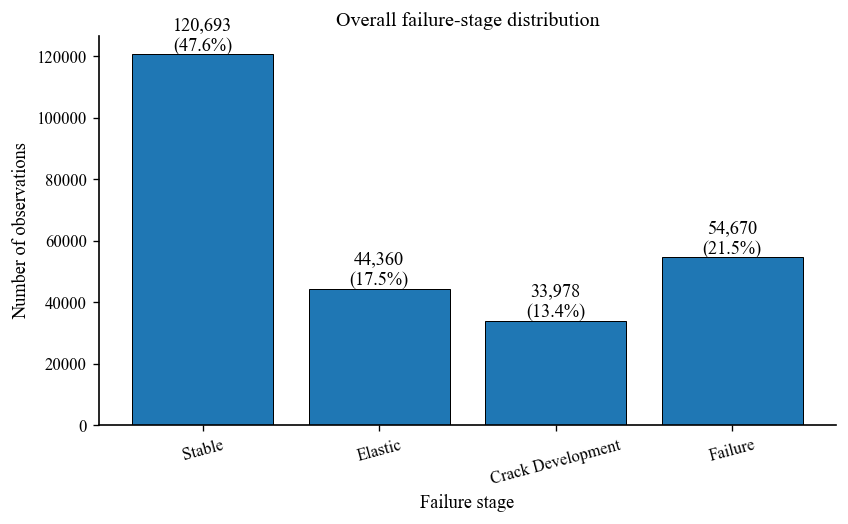

In [9]:
# ============================================================
# 9. Figure 1 — Overall failure-stage distribution
# ============================================================

fig, ax = plt.subplots(figsize=(7.2, 4.5))

bars = ax.bar(
    stage_distribution["Failure_Stage"],
    stage_distribution["Rows"],
    edgecolor="black",
    linewidth=0.6
)

ax.set_xlabel("Failure stage")
ax.set_ylabel("Number of observations")
ax.set_title("Overall failure-stage distribution")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

for bar, count, percentage in zip(
    bars,
    stage_distribution["Rows"],
    stage_distribution["Percentage"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(count):,}\n({percentage:.1f}%)",
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=15)

fig.savefig(
    FIGURE_DIR / "Figure_01_overall_stage_distribution.png",
    bbox_inches="tight"
)
fig.savefig(
    FIGURE_DIR / "Figure_01_overall_stage_distribution.tiff",
    bbox_inches="tight"
)
plt.show()


## Representative specimens: lowest and highest strength at each curing age

For each curing day, two representative specimens are selected:

- the specimen with the **lowest peak stress**;
- the specimen with the **highest peak stress**.

This selection affects only the representative figures. All specimens remain in the labelled master dataset, validation tables, class distributions, and later machine-learning analysis.

The representative figures use dual y-axes to compare mechanical and infrared evolution clearly.


In [10]:
# ============================================================
# 10. Load curing-day metadata and select lowest/highest strength
# ============================================================

# The synchronized master dataset currently does not contain curing age.
# Therefore, load exp_samp.xlsx directly and merge Curing_Day by specimen ID.

METADATA_FILE = PROJECT_DIR / "exp_samp.xlsx"

if not METADATA_FILE.exists():
    raise FileNotFoundError(
        f"Metadata file not found: {METADATA_FILE}\n"
        "Place exp_samp.xlsx in the project root directory."
    )

metadata = pd.read_excel(
    METADATA_FILE,
    sheet_name="Sheet1"
)

metadata.columns = [str(column).strip() for column in metadata.columns]

# Verified metadata columns:
#   New_Sample_ID
#   Curing_Day
required_metadata_columns = [
    "New_Sample_ID",
    "Curing_Day"
]

missing_metadata_columns = [
    column for column in required_metadata_columns
    if column not in metadata.columns
]

if missing_metadata_columns:
    raise KeyError(
        f"Metadata is missing required columns: {missing_metadata_columns}\n"
        f"Available columns: {metadata.columns.tolist()}"
    )

def normalize_metadata_sample_id(value):
    text = str(value).strip().upper()
    text = text.replace("_", "-")
    text = re.sub(r"\s+", "", text)
    text = re.sub(r"-+", "-", text)
    return text.strip("-")

metadata["Sample_ID"] = (
    metadata["New_Sample_ID"]
    .map(normalize_metadata_sample_id)
)

metadata["Curing_Day"] = pd.to_numeric(
    metadata["Curing_Day"],
    errors="coerce"
)

metadata_for_merge = (
    metadata[
        [
            "Sample_ID",
            "Curing_Day"
        ]
    ]
    .dropna(subset=["Sample_ID", "Curing_Day"])
    .drop_duplicates("Sample_ID")
)

# Remove an old curing-age column if the notebook is re-run.
for old_column in [
    "Curing_Days",
    "Curing_Day_x",
    "Curing_Day_y"
]:
    if old_column in labelled.columns:
        labelled = labelled.drop(columns=old_column)

labelled = labelled.merge(
    metadata_for_merge,
    on="Sample_ID",
    how="left",
    validate="many_to_one"
)

missing_curing_samples = (
    labelled.loc[
        labelled["Curing_Day"].isna(),
        "Sample_ID"
    ]
    .drop_duplicates()
    .tolist()
)

if missing_curing_samples:
    print(
        "WARNING: The following specimens were not matched to metadata:",
        missing_curing_samples
    )

matched_curing_count = (
    labelled.loc[
        labelled["Curing_Day"].notna(),
        "Sample_ID"
    ]
    .nunique()
)

print(
    f"Curing-day metadata matched for "
    f"{matched_curing_count} of "
    f"{labelled['Sample_ID'].nunique()} specimens."
)

# Create one specimen-level record.
representative_base = (
    labelled.groupby(
        "Sample_ID",
        as_index=False,
        observed=True
    )
    .agg(
        Curing_Days=("Curing_Day", "first"),
        Peak_Stress_MPa=("Peak_Stress_MPa", "first"),
        Peak_Time_s=("Peak_Time_s", "first"),
        Total_Rows=("Sample_ID", "size")
    )
    .dropna(
        subset=[
            "Curing_Days",
            "Peak_Stress_MPa"
        ]
    )
)

# Select the lowest and highest peak-strength specimen at each curing age.
lowest_rows = (
    representative_base.loc[
        representative_base.groupby(
            "Curing_Days"
        )["Peak_Stress_MPa"].idxmin()
    ]
    .copy()
)
lowest_rows["Strength_Class"] = "Lowest strength"

highest_rows = (
    representative_base.loc[
        representative_base.groupby(
            "Curing_Days"
        )["Peak_Stress_MPa"].idxmax()
    ]
    .copy()
)
highest_rows["Strength_Class"] = "Highest strength"

representative_table = (
    pd.concat(
        [lowest_rows, highest_rows],
        ignore_index=True
    )
    .sort_values(
        ["Curing_Days", "Strength_Class"]
    )
    .reset_index(drop=True)
)

representative_table["Selection_Note"] = ""

for curing_day, group in representative_table.groupby("Curing_Days"):
    if group["Sample_ID"].nunique() == 1:
        representative_table.loc[
            representative_table["Curing_Days"] == curing_day,
            "Selection_Note"
        ] = "Only one valid specimen at this curing age"

representative_ids = (
    representative_table["Sample_ID"]
    .drop_duplicates()
    .tolist()
)

print("\nLowest- and highest-strength specimens selected for each curing day:")
display(representative_table)

representative_table.to_csv(
    QC_DIR / "lowest_highest_strength_specimens_by_curing_day.csv",
    index=False
)


Curing-day metadata matched for 16 of 80 specimens.

Lowest- and highest-strength specimens selected for each curing day:


,Sample_ID,Curing_Days,Peak_Stress_MPa,Peak_Time_s,Total_Rows,Strength_Class,Selection_Note
0,G2-1,3.0,11.580776,311.812,3179,Highest strength,
1,G4-1,3.0,8.234397,260.458,2560,Lowest strength,
2,G1-6,7.0,15.319822,238.399,2696,Highest strength,
3,G4-6,7.0,11.040209,333.886,3570,Lowest strength,
4,G1-11,14.0,30.371652,250.364,2277,Highest strength,
5,G4-11,14.0,5.540120,286.666,2707,Lowest strength,
6,G1-16,28.0,33.447595,328.318,3077,Highest strength,
7,G4-16,28.0,5.081754,388.237,3485,Lowest strength,


## Representative academic figures

For every curing age, the following figures use the lowest- and highest-strength specimens. All plots use one y-axis only. Failure stages are shown using consistent shaded regions and labelled stage strips. Legends are placed outside the plotting area so they do not obscure the curves.


In [11]:
# ============================================================
# 11. Academic plotting helpers
# ============================================================

def get_representative_sample(curing_day, strength_class):
    row = representative_table.loc[
        (representative_table["Curing_Days"] == curing_day) &
        (representative_table["Strength_Class"] == strength_class)
    ]

    if row.empty:
        return None, None

    sample_id = row["Sample_ID"].iloc[0]
    sample = (
        labelled.loc[labelled["Sample_ID"] == sample_id]
        .sort_values("Time_s")
        .copy()
    )
    return sample_id, sample


def add_failure_stage_regions(ax, sample, show_stage_labels=True):
    """
    Shade contiguous failure-stage regions and optionally label each region
    at the top of the axes.
    """
    stage_text = sample["Failure_Stage"].astype(str)
    segment_id = stage_text.ne(stage_text.shift()).cumsum()

    y_min, y_max = ax.get_ylim()
    y_text = y_max - 0.04 * (y_max - y_min)

    used_labels = set()

    for _, segment in sample.groupby(segment_id):
        stage_name = str(segment["Failure_Stage"].iloc[0])
        x_start = float(segment["Time_s"].min())
        x_end = float(segment["Time_s"].max())

        ax.axvspan(
            x_start,
            x_end,
            color=STAGE_COLORS[stage_name],
            alpha=0.10,
            linewidth=0
        )

        if show_stage_labels and stage_name not in used_labels:
            x_mid = (x_start + x_end) / 2
            ax.text(
                x_mid,
                y_text,
                stage_name,
                ha="center",
                va="top",
                fontsize=9,
                color=ACADEMIC_COLORS["dark_grey"],
                bbox=dict(
                    boxstyle="round,pad=0.18",
                    facecolor="white",
                    edgecolor=STAGE_COLORS[stage_name],
                    alpha=0.90
                )
            )
            used_labels.add(stage_name)


def add_stage_legend(ax):
    from matplotlib.patches import Patch

    stage_handles = [
        Patch(
            facecolor=STAGE_COLORS[stage],
            edgecolor="none",
            alpha=0.25,
            label=stage
        )
        for stage in STAGE_ORDER
    ]

    handles, labels = ax.get_legend_handles_labels()
    all_handles = handles + stage_handles
    all_labels = labels + STAGE_ORDER

    unique = {}
    for handle, label in zip(all_handles, all_labels):
        if label not in unique:
            unique[label] = handle

    ax.legend(
        unique.values(),
        unique.keys(),
        frameon=False,
        loc="upper left",
        bbox_to_anchor=(1.02, 1.0),
        borderaxespad=0.0
    )


def format_academic_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(
        axis="both",
        linestyle="--",
        linewidth=0.5,
        alpha=0.25
    )


def save_figure(fig, filename_stem):
    fig.savefig(
        FIGURE_DIR / f"{filename_stem}.png",
        bbox_inches="tight"
    )
    fig.savefig(
        FIGURE_DIR / f"{filename_stem}.tiff",
        bbox_inches="tight"
    )


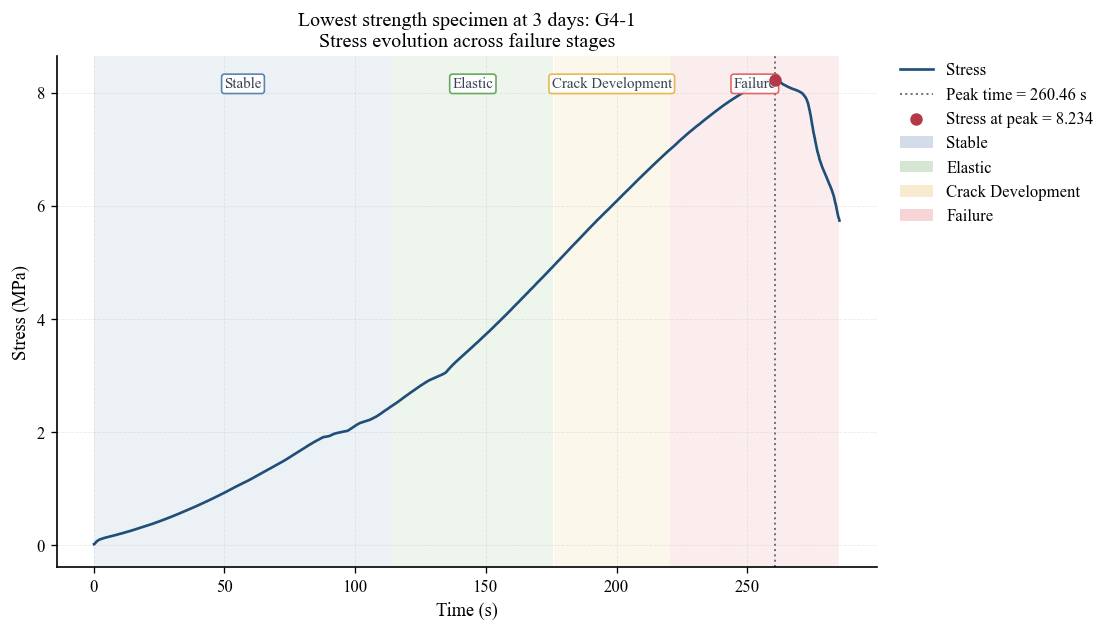

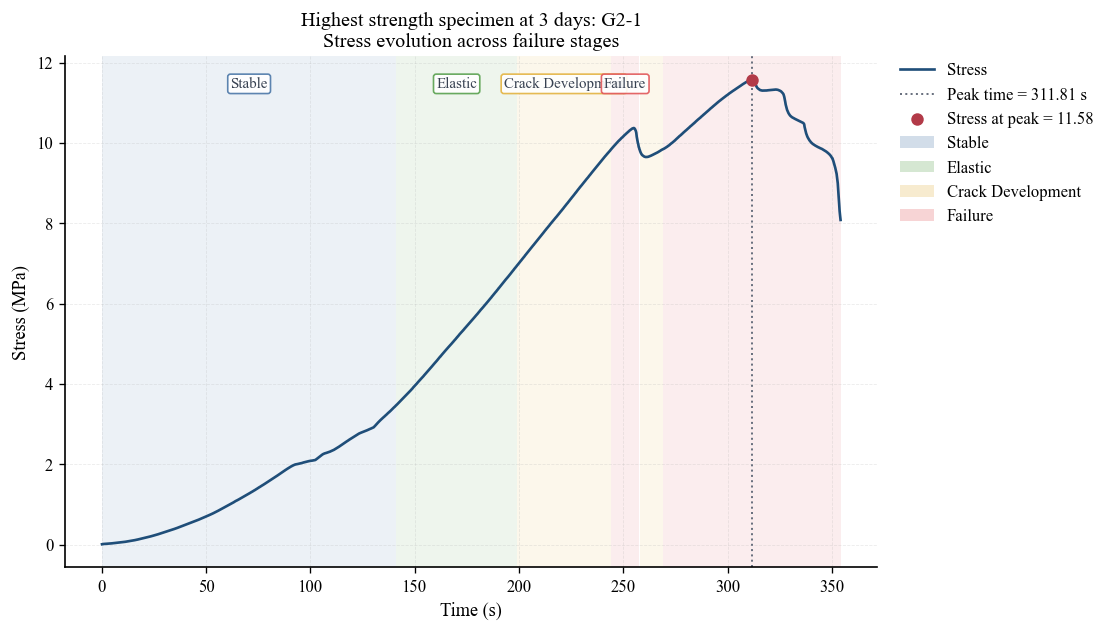

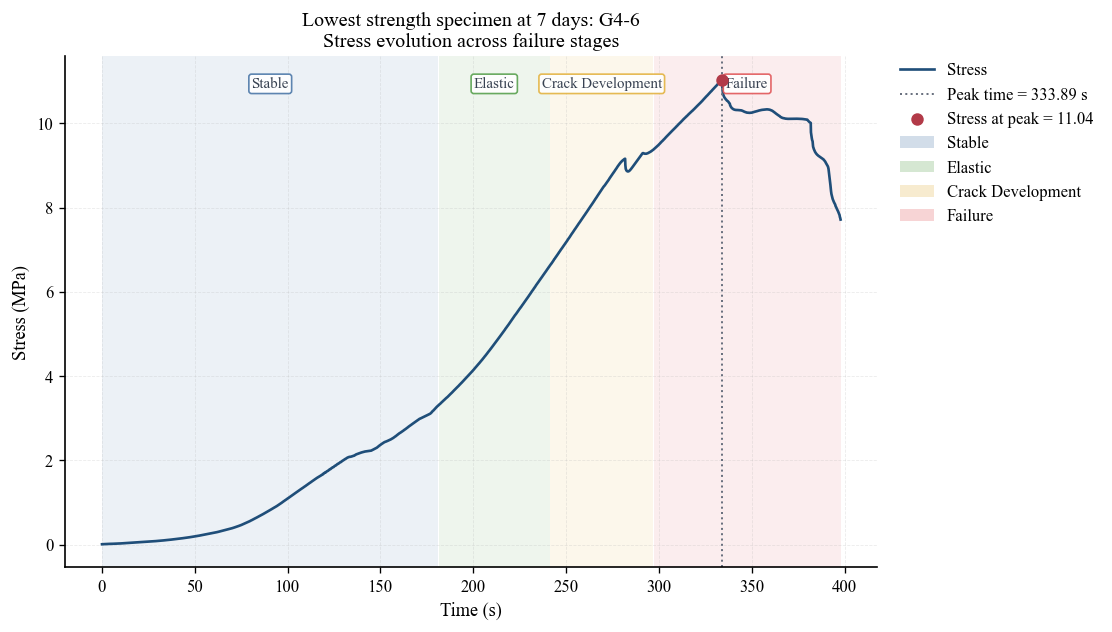

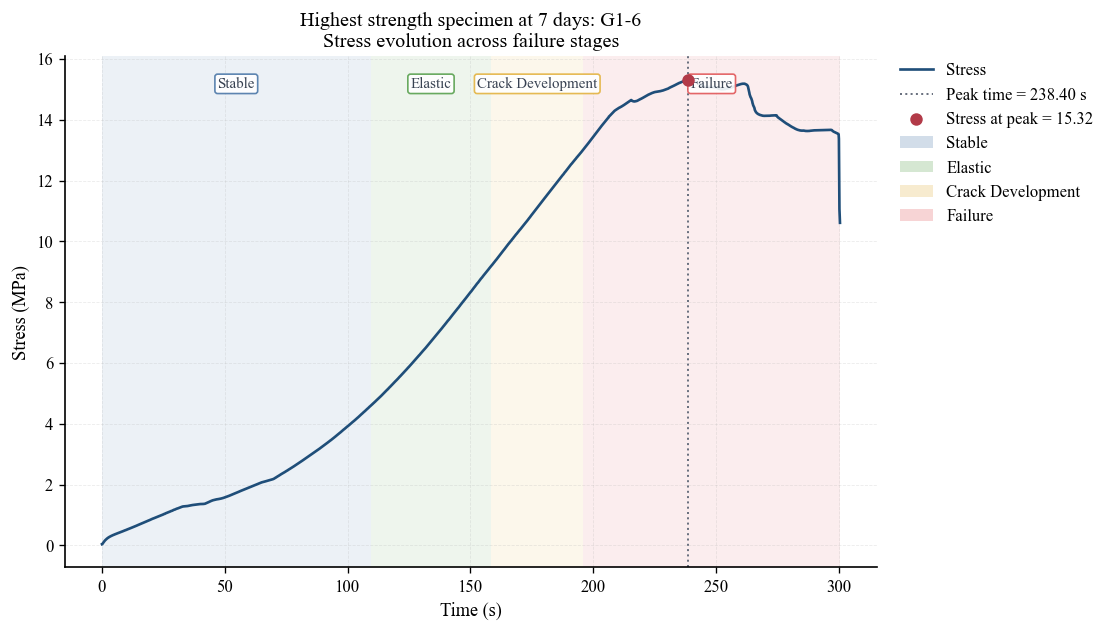

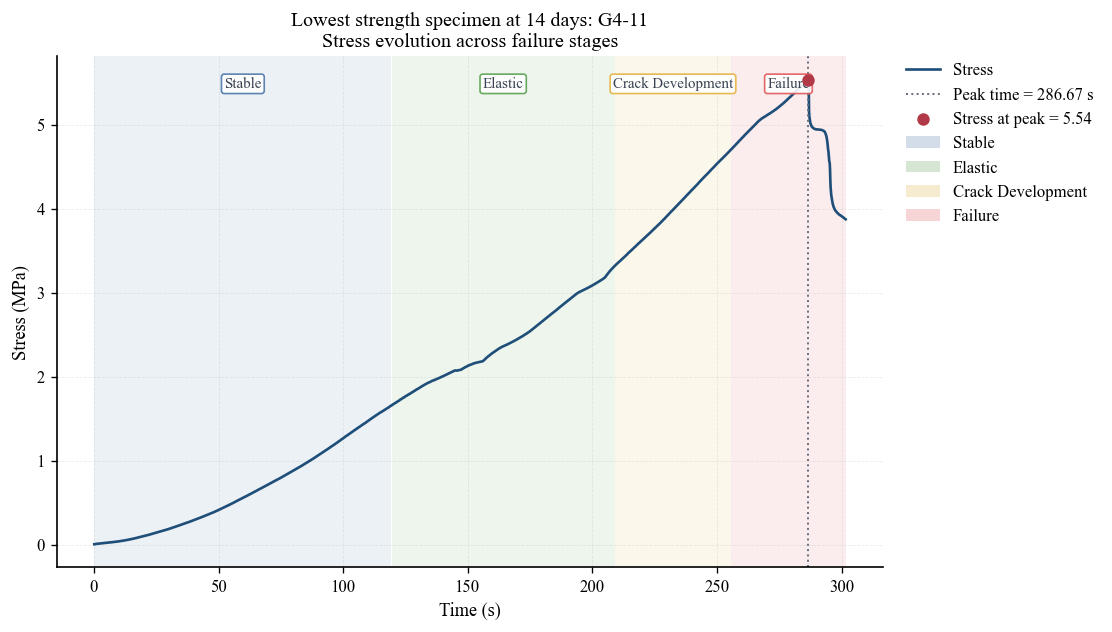

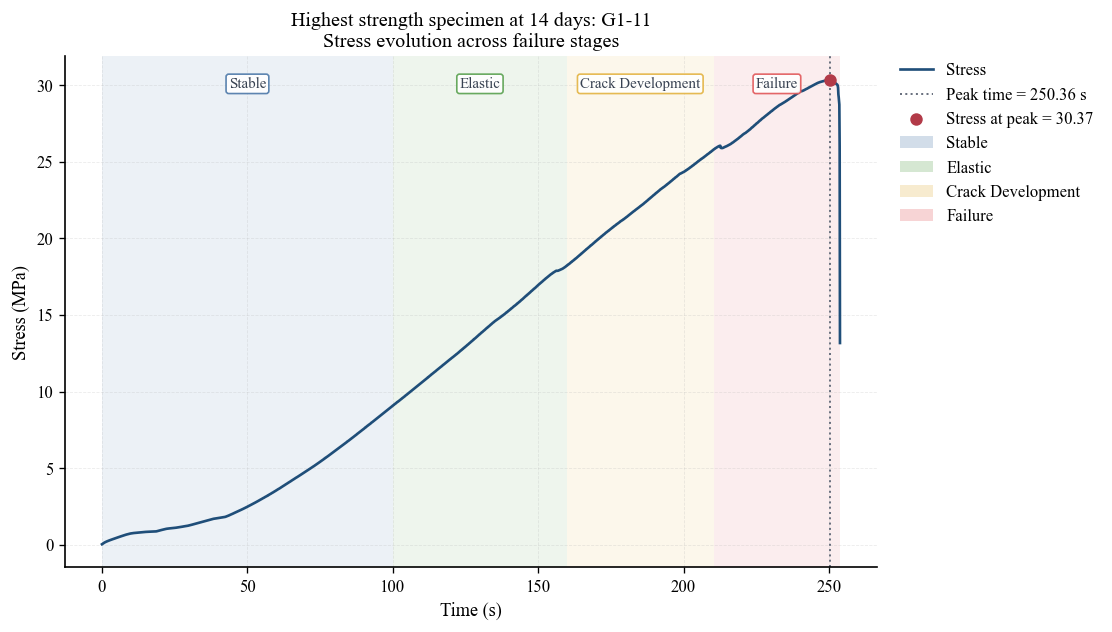

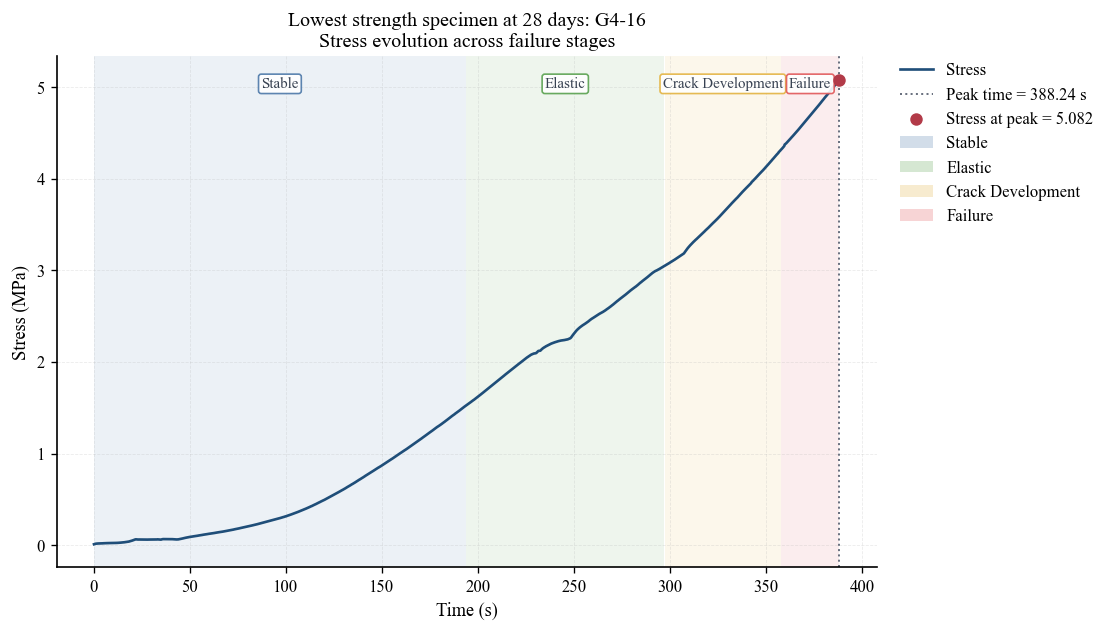

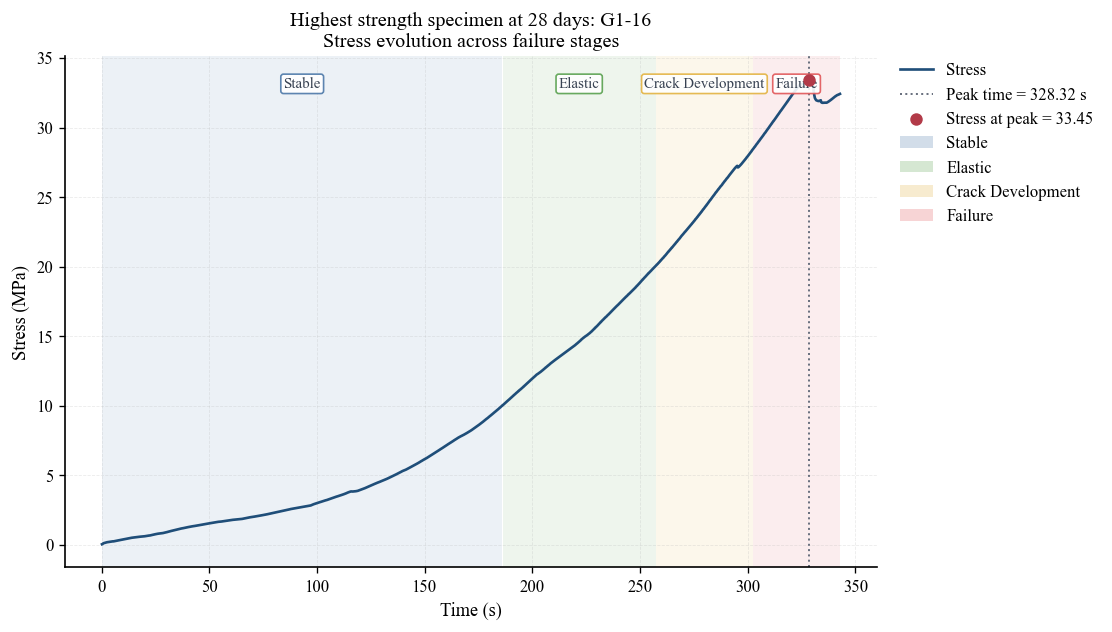

In [12]:
# ============================================================
# 12. Stress evolution with failure stages
# ============================================================

for curing_day in sorted(representative_table["Curing_Days"].unique()):
    for strength_class in ["Lowest strength", "Highest strength"]:
        sample_id, sample = get_representative_sample(
            curing_day,
            strength_class
        )
        if sample is None:
            continue

        fig, ax = plt.subplots(figsize=(9.4, 5.4))

        ax.plot(
            sample["Time_s"],
            sample["Stress_MPa"],
            color=ACADEMIC_COLORS["navy"],
            linewidth=1.6,
            label="Stress"
        )

        peak_time = float(sample["Peak_Time_s"].iloc[0])
        peak_idx = (sample["Time_s"] - peak_time).abs().idxmin()
        value_at_peak = float(sample.loc[peak_idx, "Stress_MPa"])

        ax.axvline(
            peak_time,
            color=ACADEMIC_COLORS["grey"],
            linestyle=":",
            linewidth=1.2,
            label=f"Peak time = {peak_time:.2f} s"
        )
        ax.scatter(
            peak_time,
            value_at_peak,
            color=ACADEMIC_COLORS["red"],
            marker="o",
            s=42,
            zorder=5,
            label=f"Stress at peak = {value_at_peak:.4g}"
        )

        ax.set_xlabel("Time (s)")
        ax.set_ylabel("Stress (MPa)")
        ax.set_title(
            f"{strength_class} specimen at {curing_day:g} days: {sample_id}\n"
            "Stress evolution across failure stages"
        )

        format_academic_axis(ax)

        # Draw stage regions after limits are established.
        current_ylim = ax.get_ylim()
        add_failure_stage_regions(ax, sample, show_stage_labels=True)
        ax.set_ylim(current_ylim)

        add_stage_legend(ax)

        safe_class = strength_class.lower().replace(" ", "_")
        save_figure(
            fig,
            f"Figure_12_Stress_MPa_{curing_day:g}d_{safe_class}_{sample_id}"
        )
        plt.show()


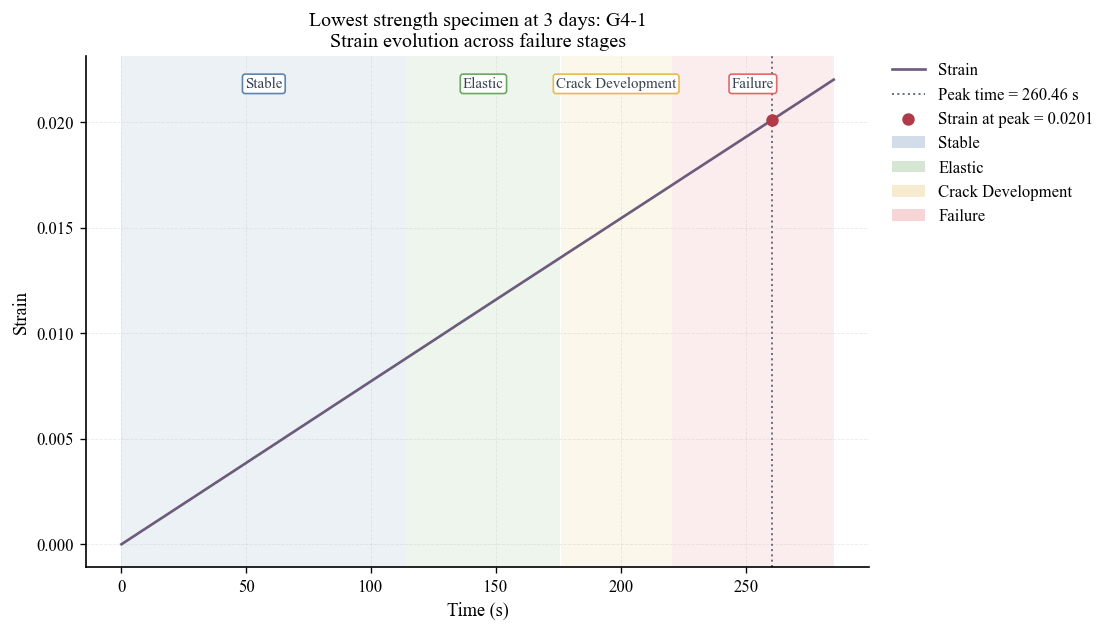

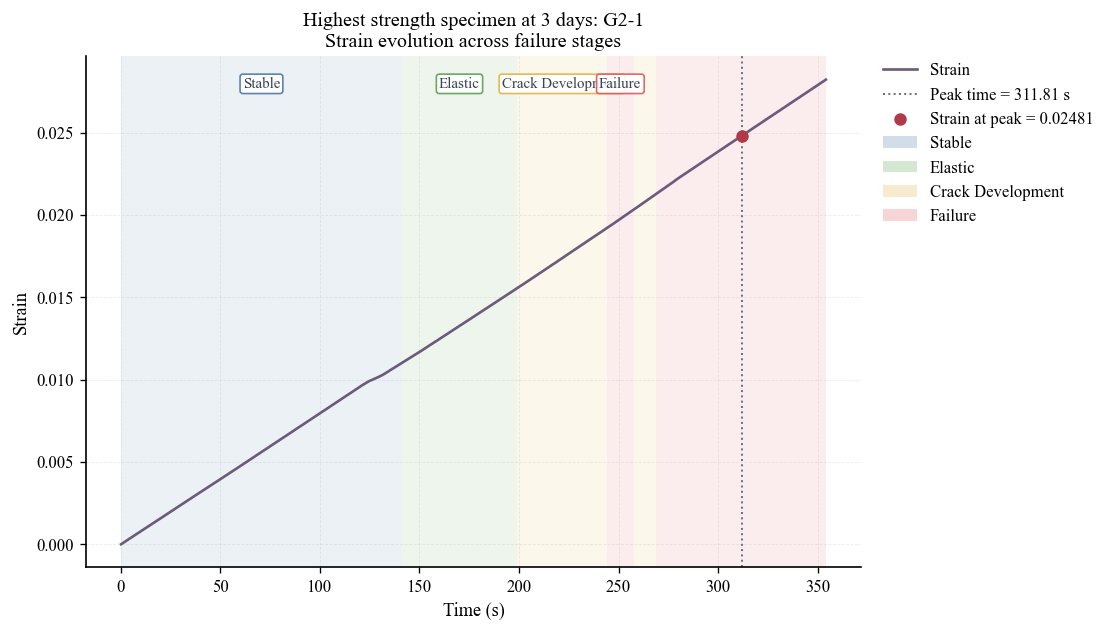

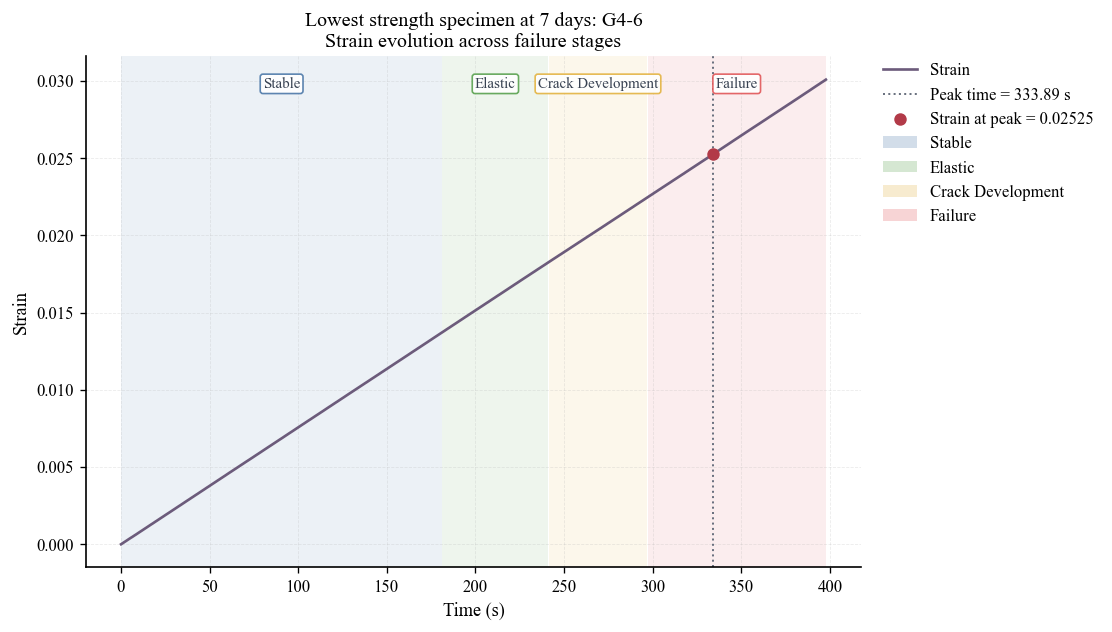

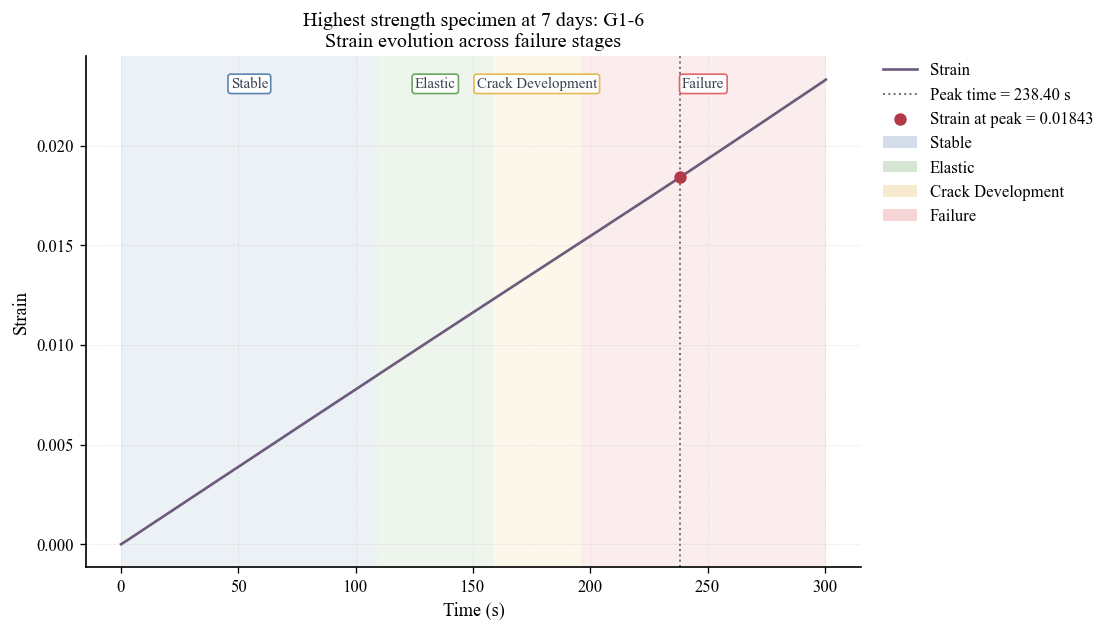

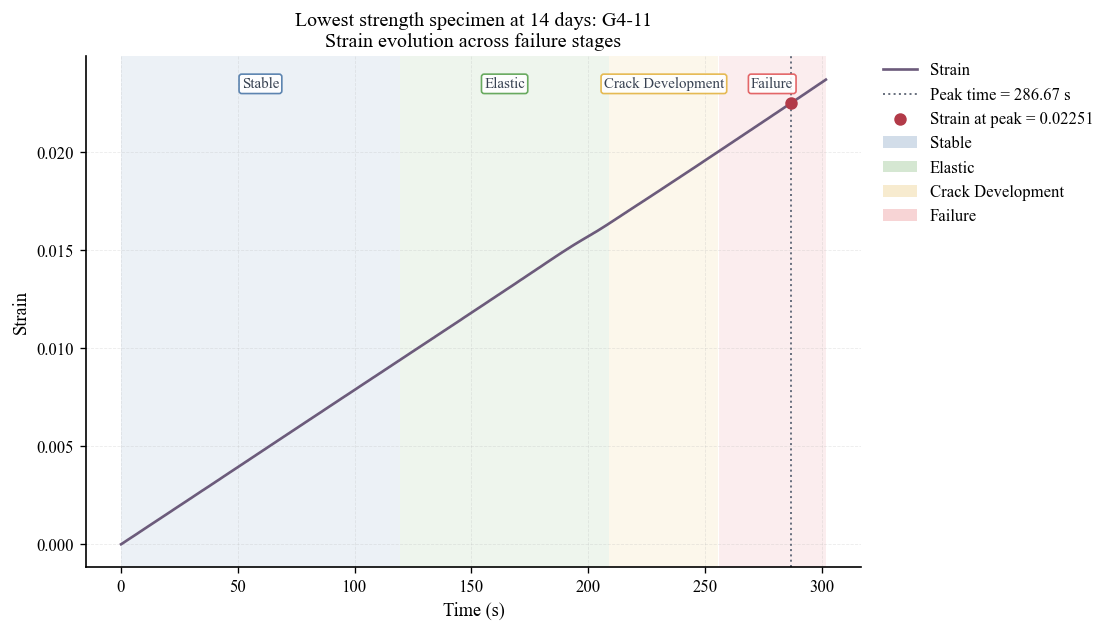

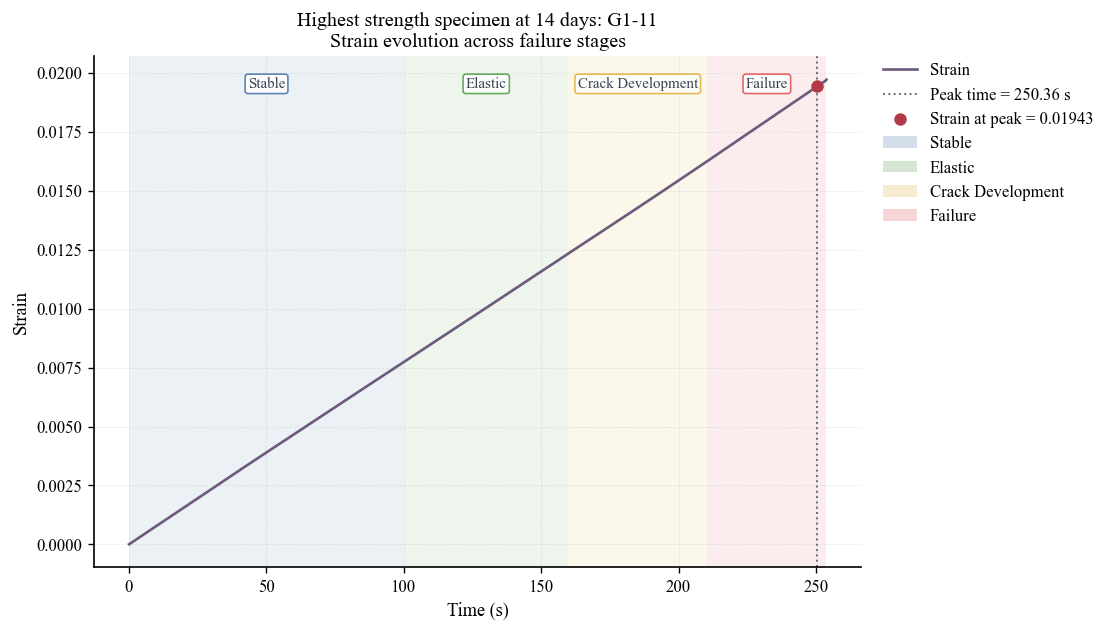

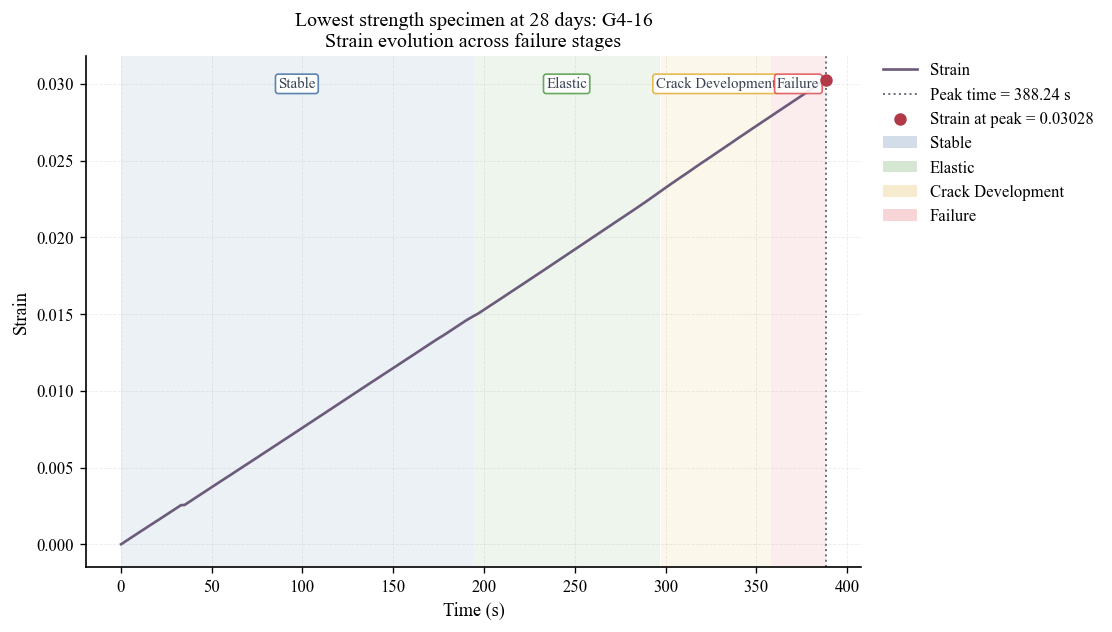

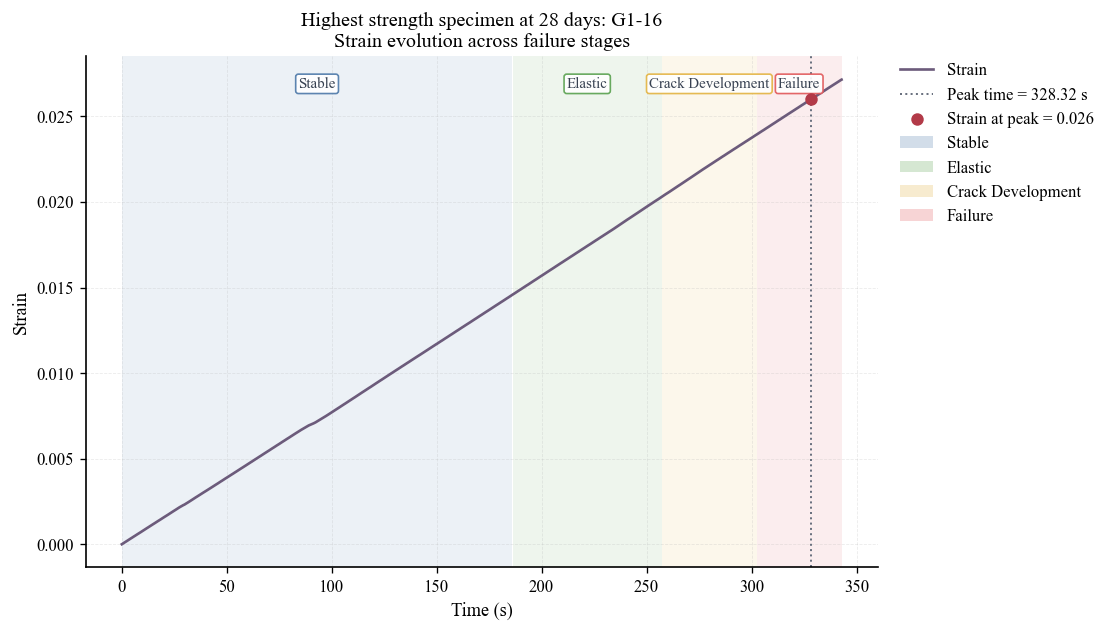

In [13]:
# ============================================================
# 13. Strain evolution with failure stages
# ============================================================

for curing_day in sorted(representative_table["Curing_Days"].unique()):
    for strength_class in ["Lowest strength", "Highest strength"]:
        sample_id, sample = get_representative_sample(
            curing_day,
            strength_class
        )
        if sample is None:
            continue

        fig, ax = plt.subplots(figsize=(9.4, 5.4))

        ax.plot(
            sample["Time_s"],
            sample["Strain"],
            color=ACADEMIC_COLORS["purple"],
            linewidth=1.6,
            label="Strain"
        )

        peak_time = float(sample["Peak_Time_s"].iloc[0])
        peak_idx = (sample["Time_s"] - peak_time).abs().idxmin()
        value_at_peak = float(sample.loc[peak_idx, "Strain"])

        ax.axvline(
            peak_time,
            color=ACADEMIC_COLORS["grey"],
            linestyle=":",
            linewidth=1.2,
            label=f"Peak time = {peak_time:.2f} s"
        )
        ax.scatter(
            peak_time,
            value_at_peak,
            color=ACADEMIC_COLORS["red"],
            marker="o",
            s=42,
            zorder=5,
            label=f"Strain at peak = {value_at_peak:.4g}"
        )

        ax.set_xlabel("Time (s)")
        ax.set_ylabel("Strain")
        ax.set_title(
            f"{strength_class} specimen at {curing_day:g} days: {sample_id}\n"
            "Strain evolution across failure stages"
        )

        format_academic_axis(ax)

        # Draw stage regions after limits are established.
        current_ylim = ax.get_ylim()
        add_failure_stage_regions(ax, sample, show_stage_labels=True)
        ax.set_ylim(current_ylim)

        add_stage_legend(ax)

        safe_class = strength_class.lower().replace(" ", "_")
        save_figure(
            fig,
            f"Figure_13_Strain_{curing_day:g}d_{safe_class}_{sample_id}"
        )
        plt.show()


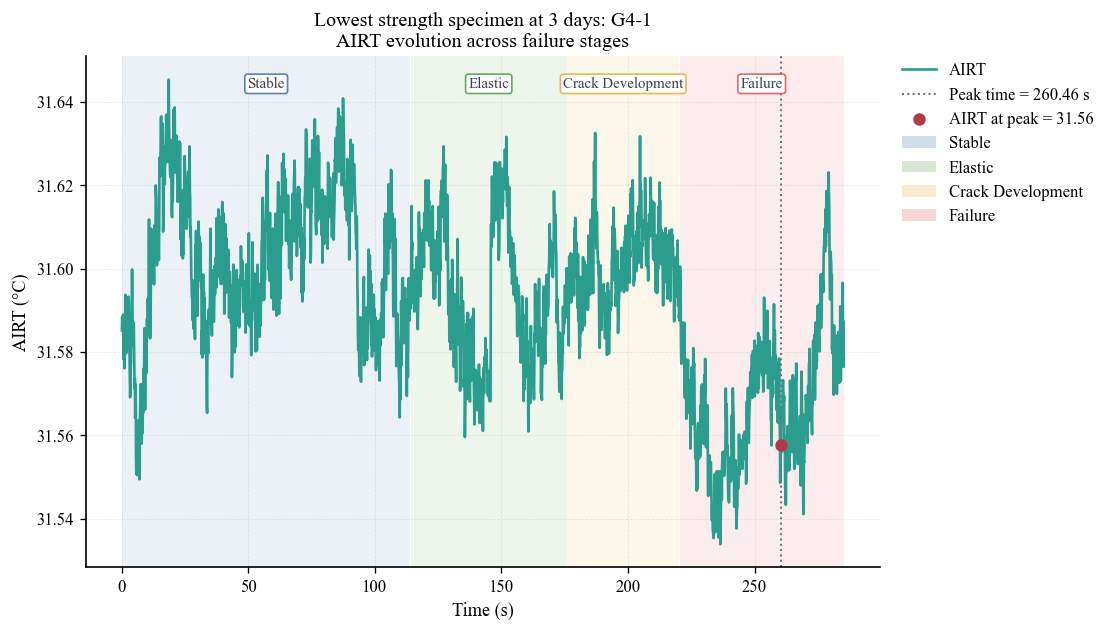

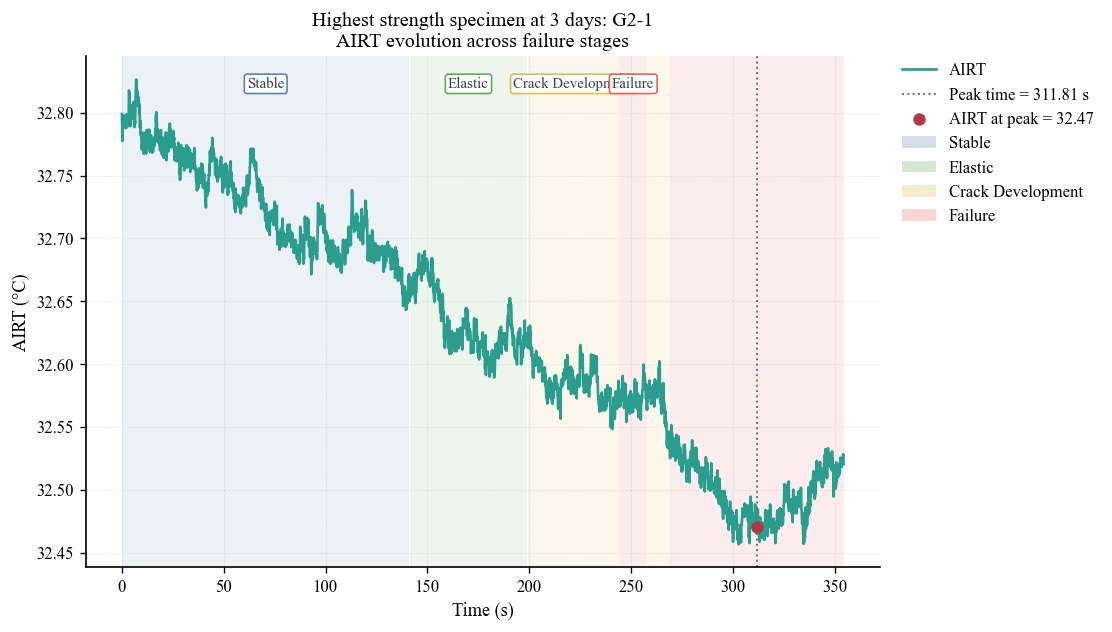

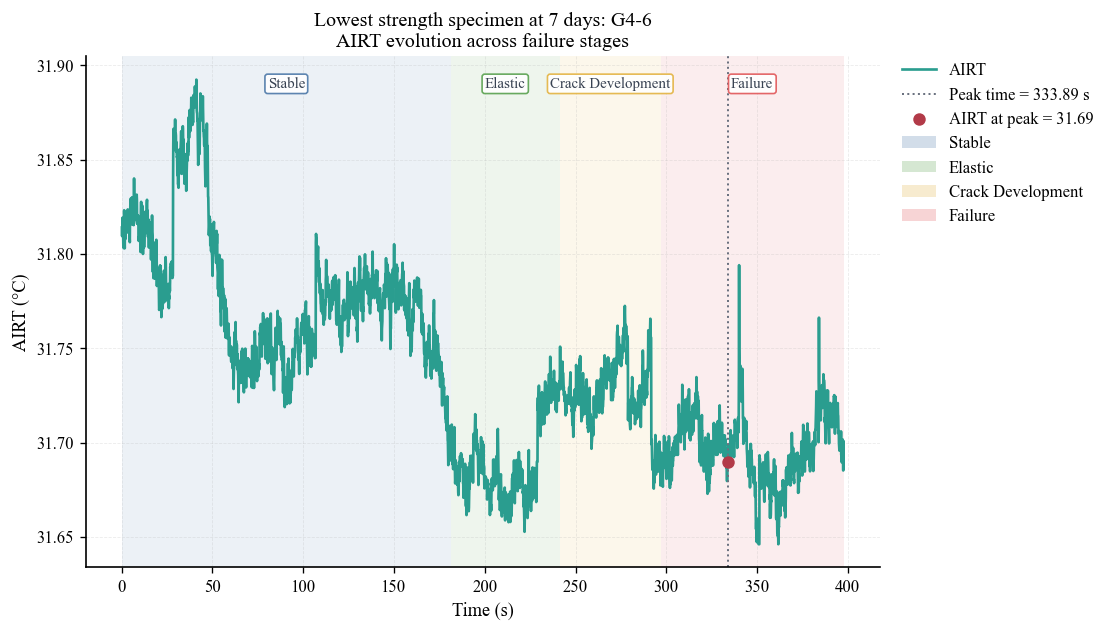

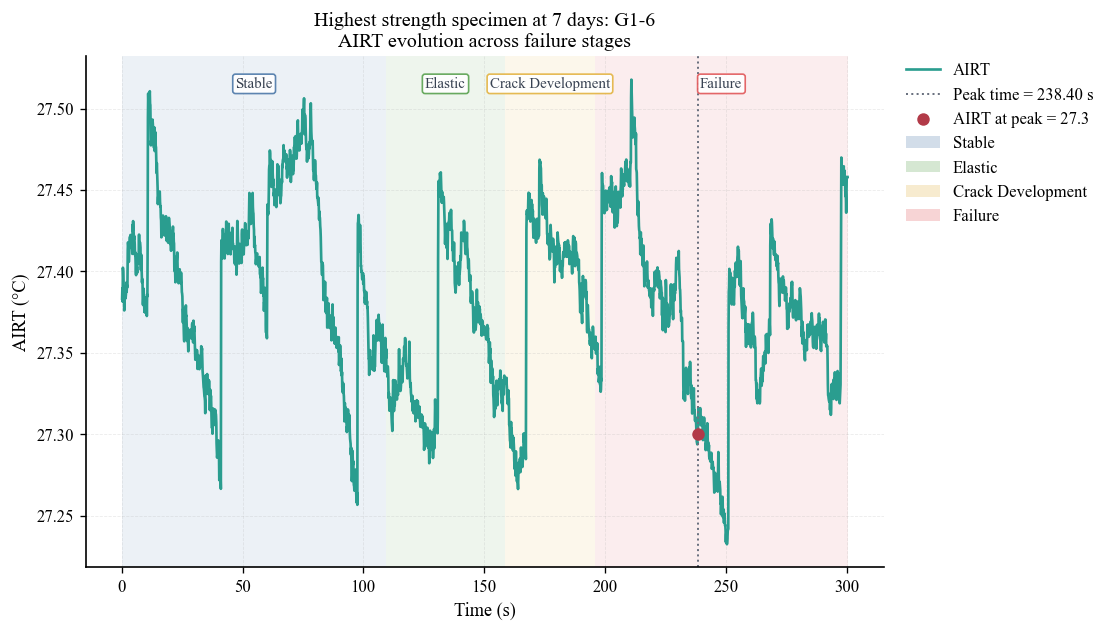

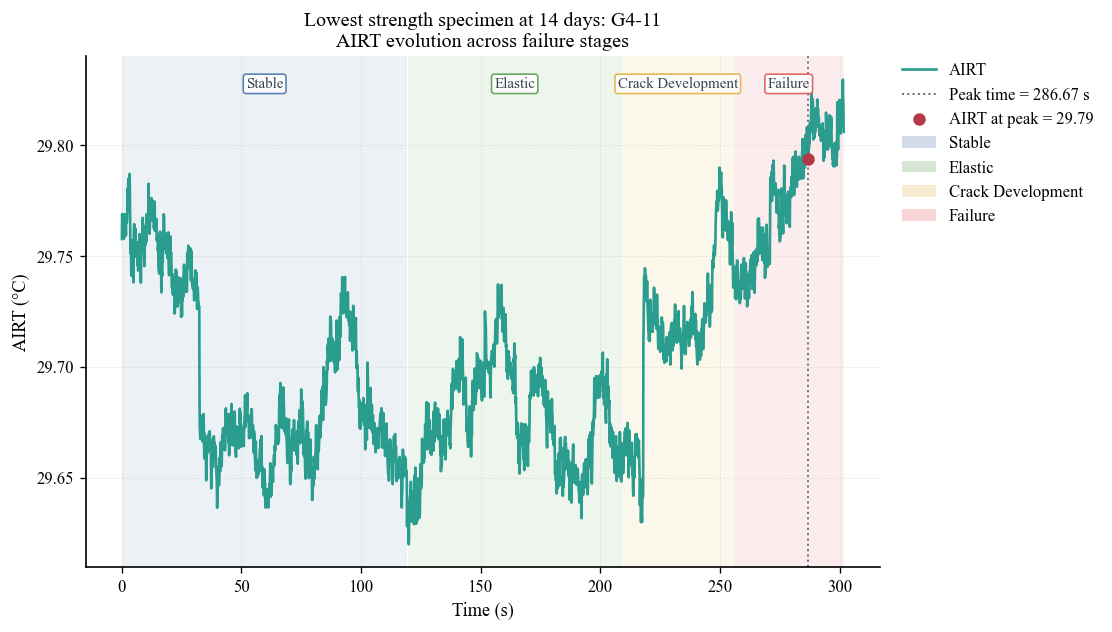

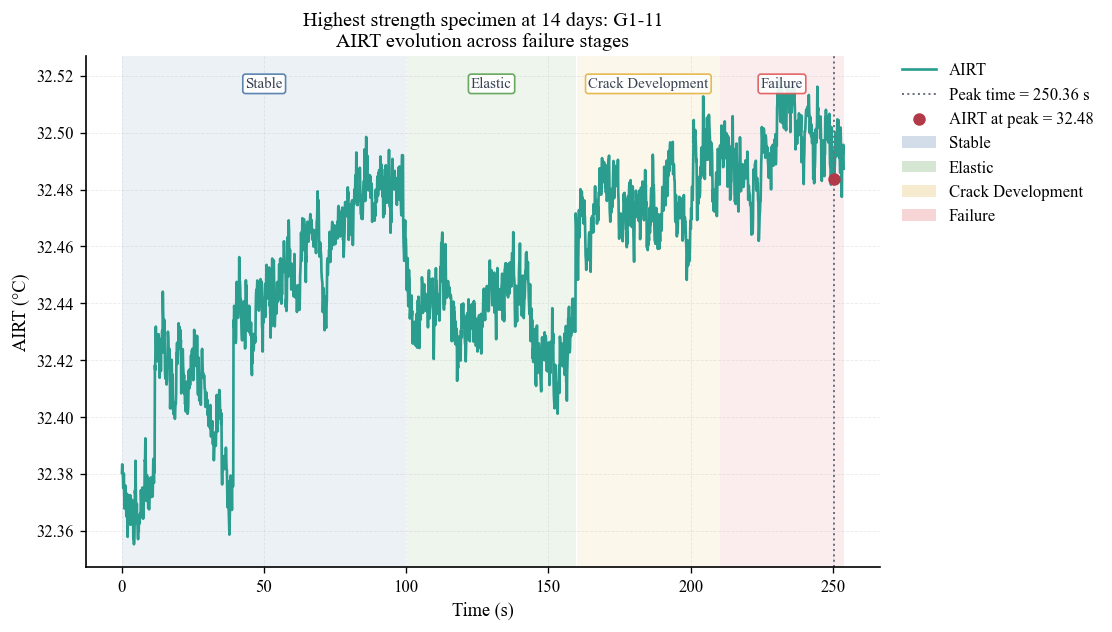

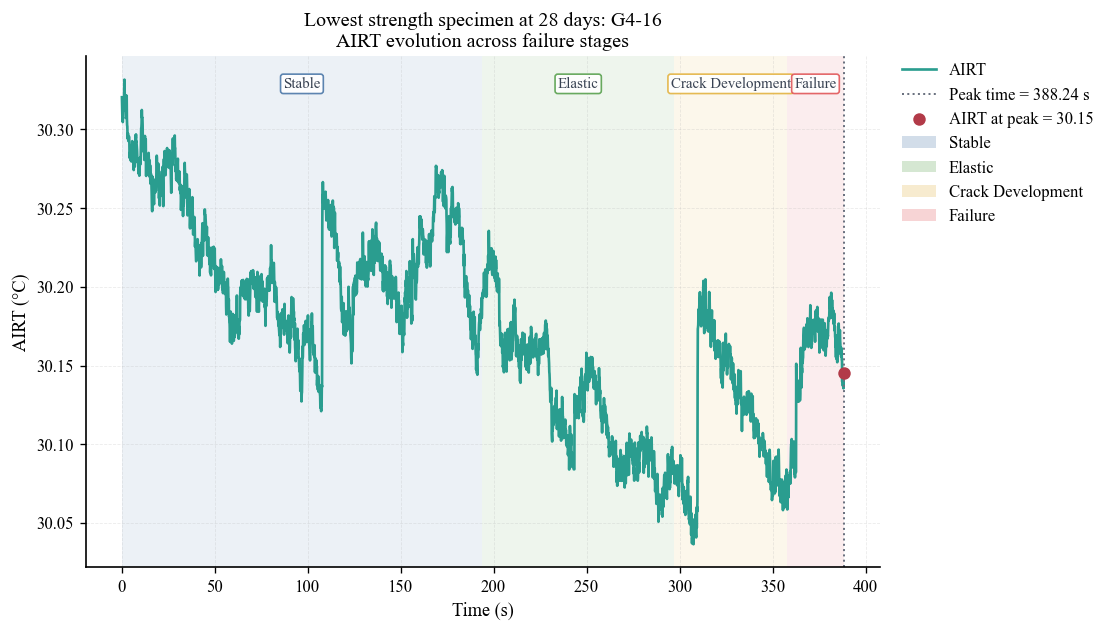

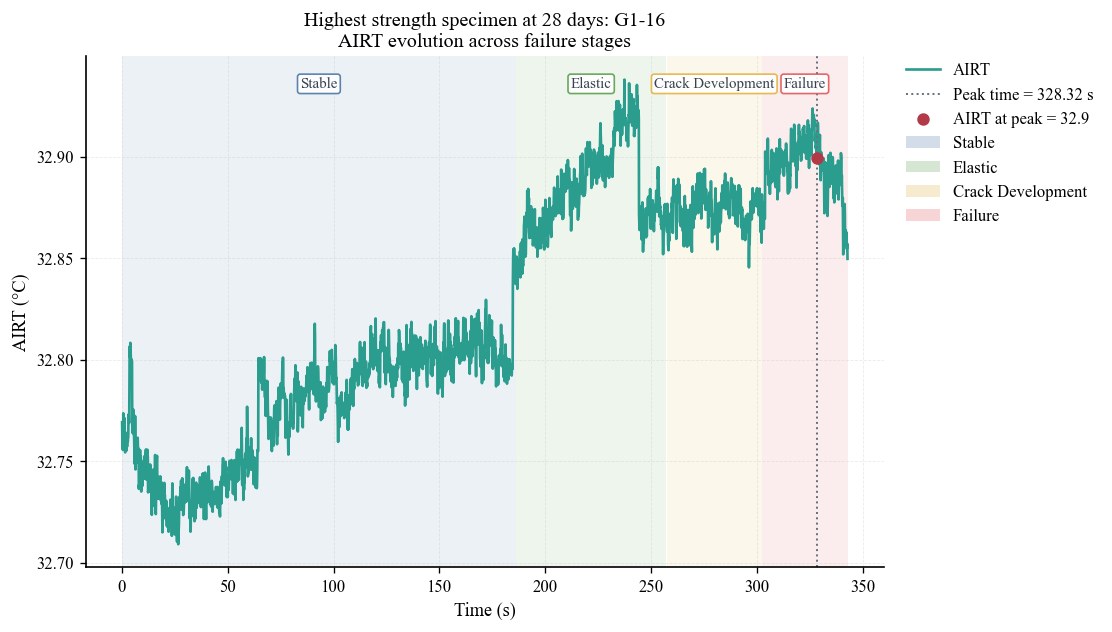

In [14]:
# ============================================================
# 14. AIRT evolution with failure stages
# ============================================================

for curing_day in sorted(representative_table["Curing_Days"].unique()):
    for strength_class in ["Lowest strength", "Highest strength"]:
        sample_id, sample = get_representative_sample(
            curing_day,
            strength_class
        )
        if sample is None:
            continue

        fig, ax = plt.subplots(figsize=(9.4, 5.4))

        ax.plot(
            sample["Time_s"],
            sample["AIRT_C"],
            color=ACADEMIC_COLORS["teal"],
            linewidth=1.6,
            label="AIRT"
        )

        peak_time = float(sample["Peak_Time_s"].iloc[0])
        peak_idx = (sample["Time_s"] - peak_time).abs().idxmin()
        value_at_peak = float(sample.loc[peak_idx, "AIRT_C"])

        ax.axvline(
            peak_time,
            color=ACADEMIC_COLORS["grey"],
            linestyle=":",
            linewidth=1.2,
            label=f"Peak time = {peak_time:.2f} s"
        )
        ax.scatter(
            peak_time,
            value_at_peak,
            color=ACADEMIC_COLORS["red"],
            marker="o",
            s=42,
            zorder=5,
            label=f"AIRT at peak = {value_at_peak:.4g}"
        )

        ax.set_xlabel("Time (s)")
        ax.set_ylabel("AIRT (°C)")
        ax.set_title(
            f"{strength_class} specimen at {curing_day:g} days: {sample_id}\n"
            "AIRT evolution across failure stages"
        )

        format_academic_axis(ax)

        # Draw stage regions after limits are established.
        current_ylim = ax.get_ylim()
        add_failure_stage_regions(ax, sample, show_stage_labels=True)
        ax.set_ylim(current_ylim)

        add_stage_legend(ax)

        safe_class = strength_class.lower().replace(" ", "_")
        save_figure(
            fig,
            f"Figure_14_AIRT_C_{curing_day:g}d_{safe_class}_{sample_id}"
        )
        plt.show()


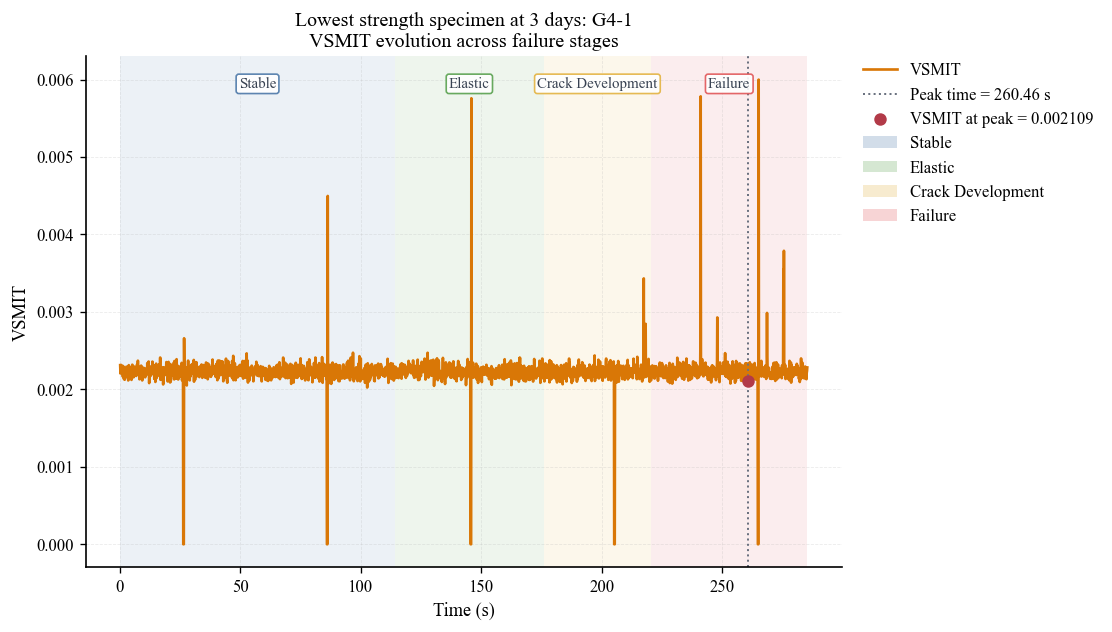

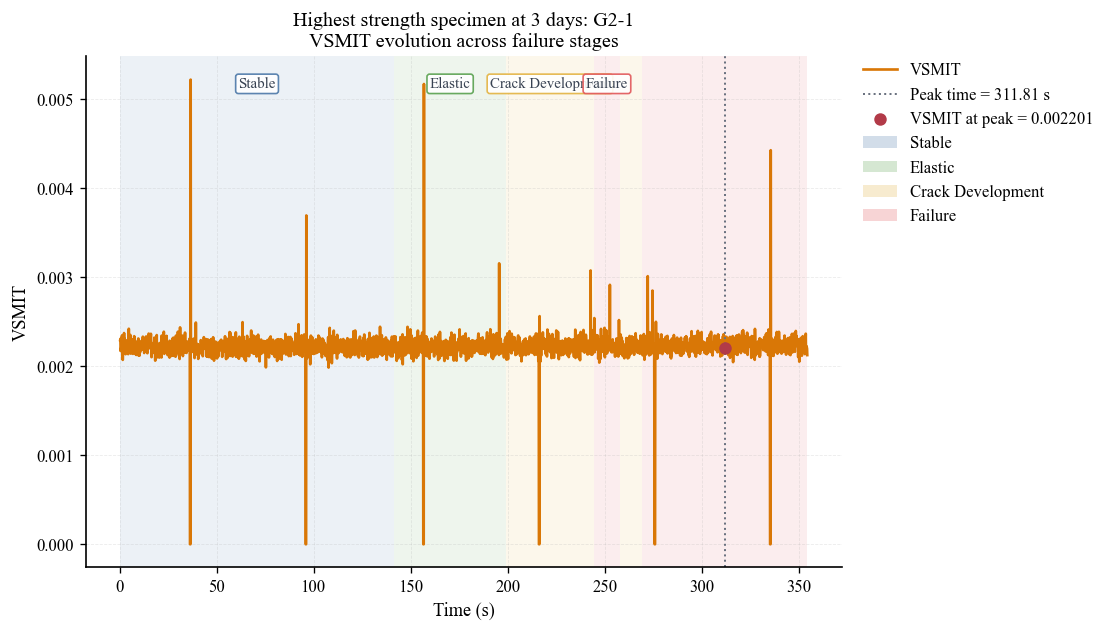

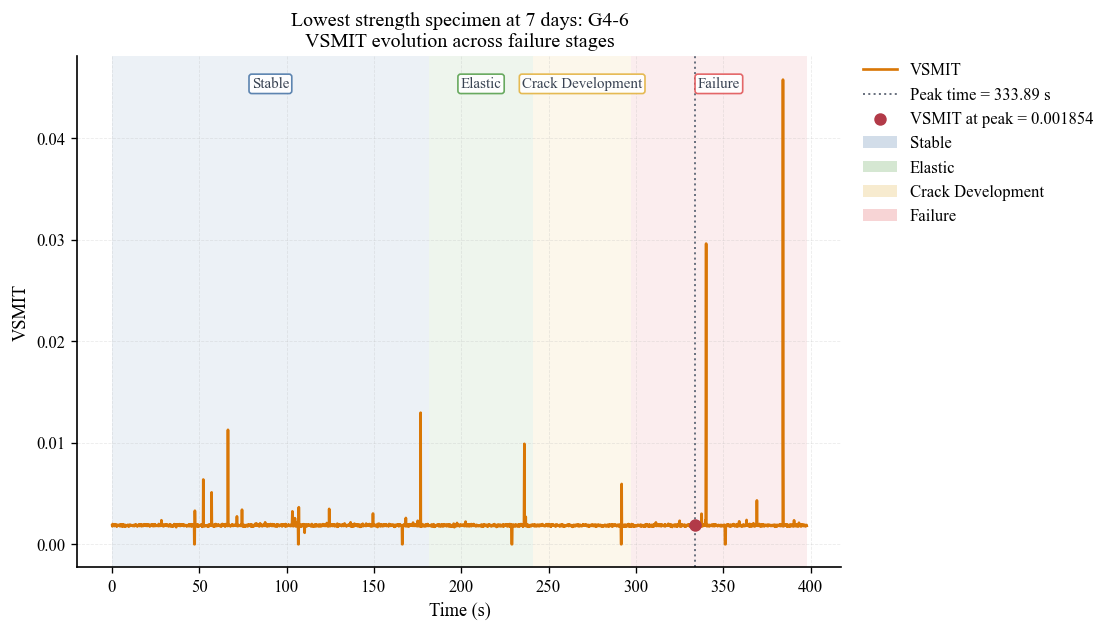

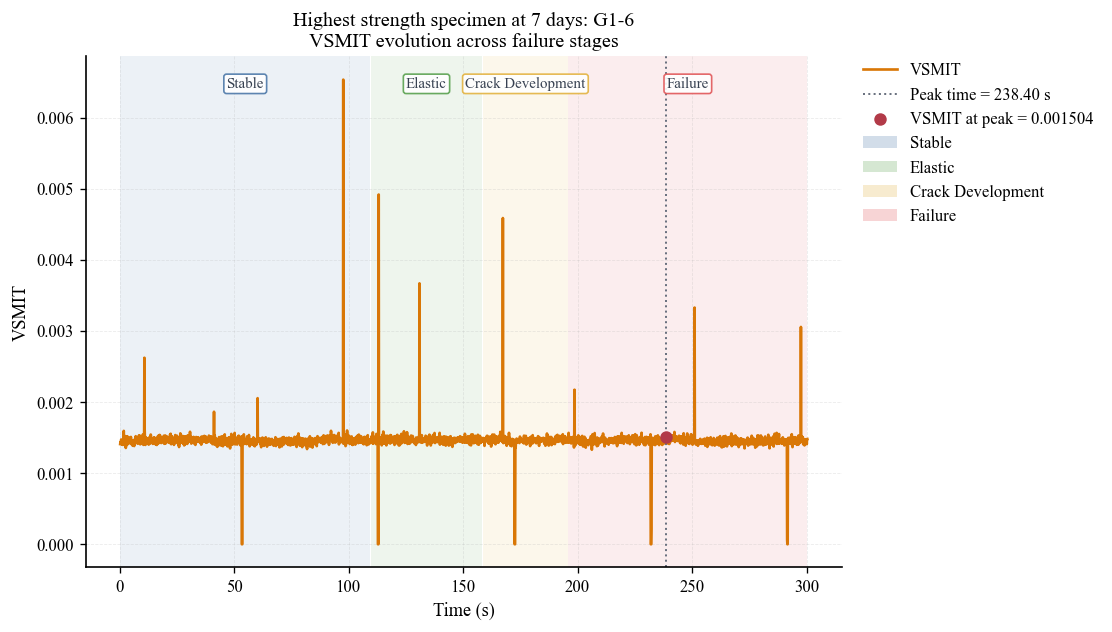

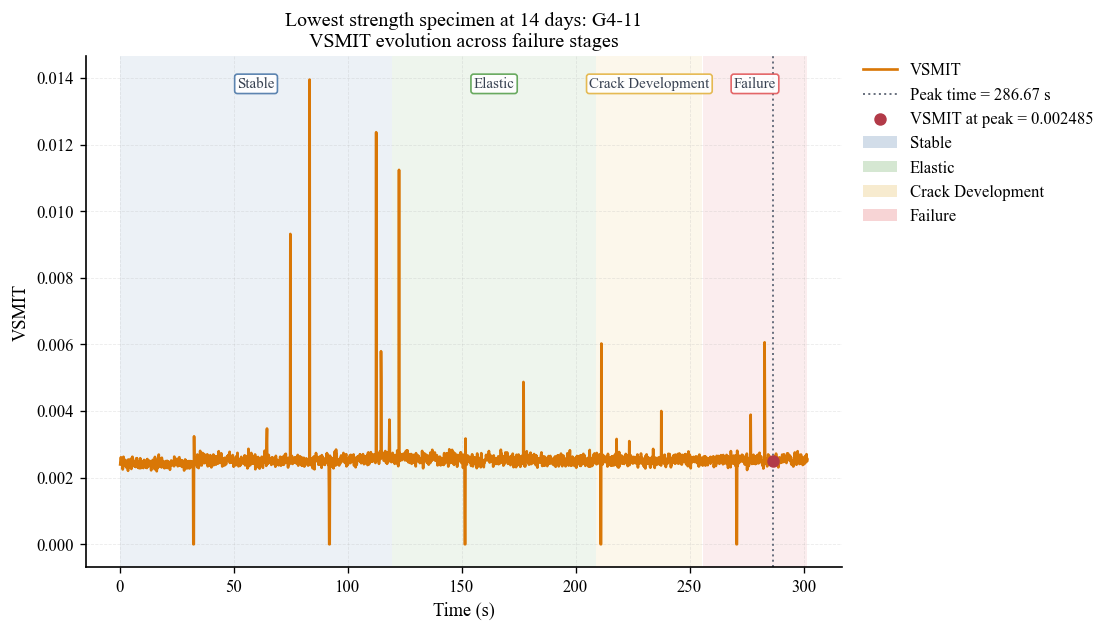

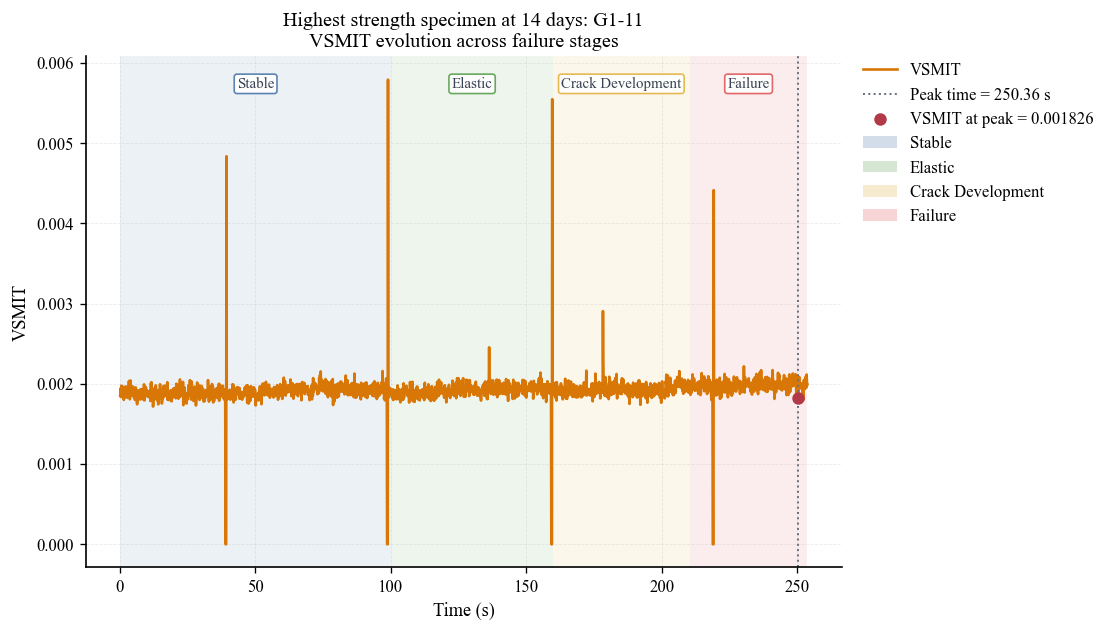

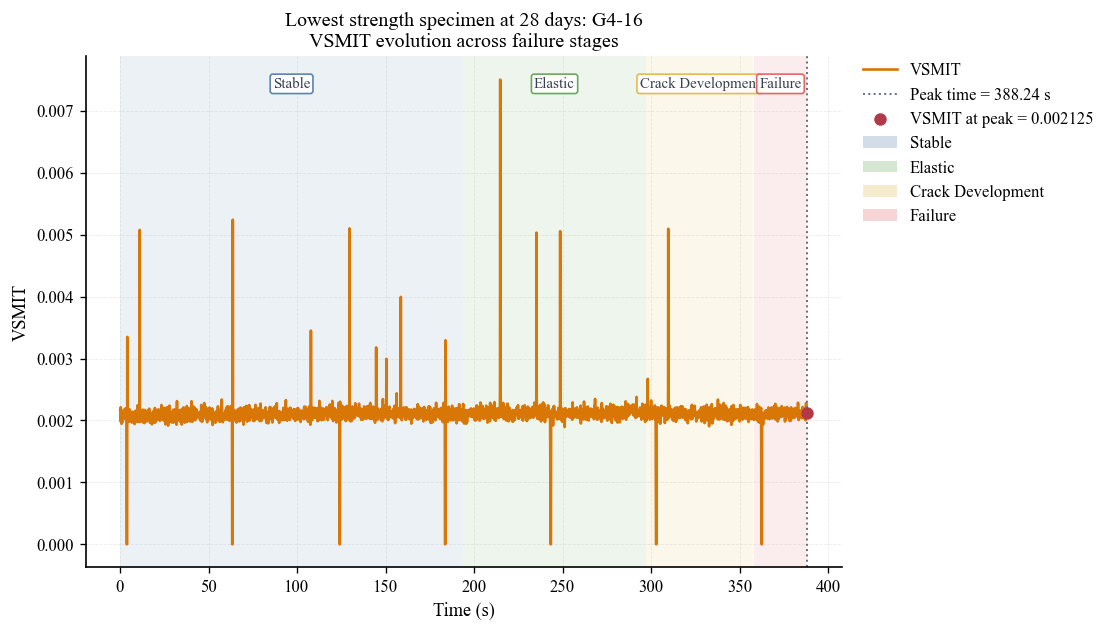

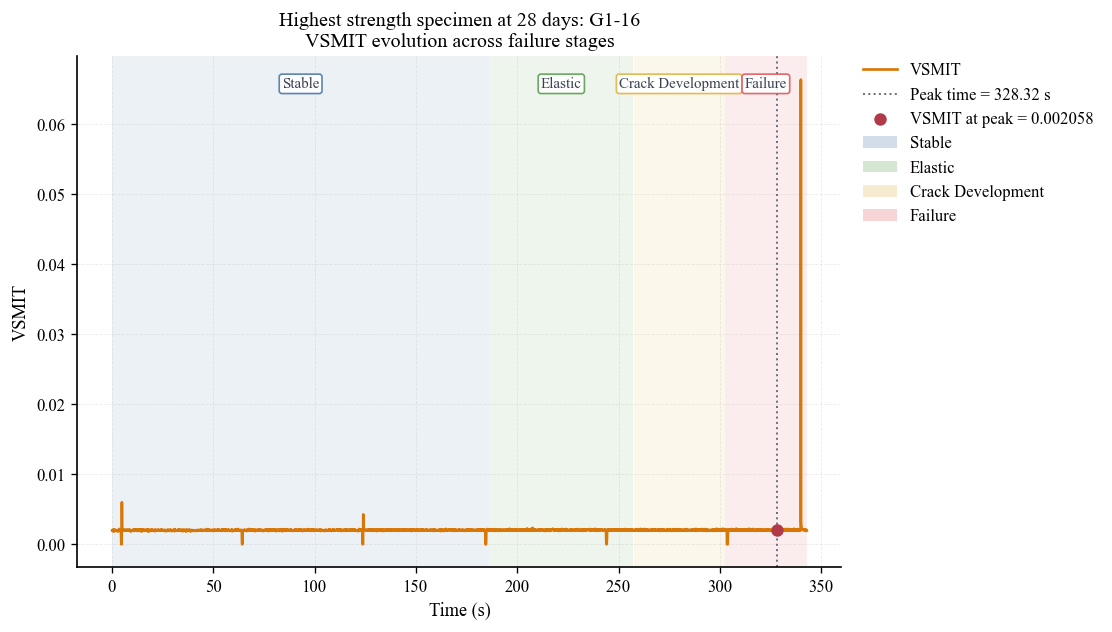

In [15]:
# ============================================================
# 15. VSMIT evolution with failure stages
# ============================================================

for curing_day in sorted(representative_table["Curing_Days"].unique()):
    for strength_class in ["Lowest strength", "Highest strength"]:
        sample_id, sample = get_representative_sample(
            curing_day,
            strength_class
        )
        if sample is None:
            continue

        fig, ax = plt.subplots(figsize=(9.4, 5.4))

        ax.plot(
            sample["Time_s"],
            sample["VSMIT"],
            color=ACADEMIC_COLORS["orange"],
            linewidth=1.6,
            label="VSMIT"
        )

        peak_time = float(sample["Peak_Time_s"].iloc[0])
        peak_idx = (sample["Time_s"] - peak_time).abs().idxmin()
        value_at_peak = float(sample.loc[peak_idx, "VSMIT"])

        ax.axvline(
            peak_time,
            color=ACADEMIC_COLORS["grey"],
            linestyle=":",
            linewidth=1.2,
            label=f"Peak time = {peak_time:.2f} s"
        )
        ax.scatter(
            peak_time,
            value_at_peak,
            color=ACADEMIC_COLORS["red"],
            marker="o",
            s=42,
            zorder=5,
            label=f"VSMIT at peak = {value_at_peak:.4g}"
        )

        ax.set_xlabel("Time (s)")
        ax.set_ylabel("VSMIT")
        ax.set_title(
            f"{strength_class} specimen at {curing_day:g} days: {sample_id}\n"
            "VSMIT evolution across failure stages"
        )

        format_academic_axis(ax)

        # Draw stage regions after limits are established.
        current_ylim = ax.get_ylim()
        add_failure_stage_regions(ax, sample, show_stage_labels=True)
        ax.set_ylim(current_ylim)

        add_stage_legend(ax)

        safe_class = strength_class.lower().replace(" ", "_")
        save_figure(
            fig,
            f"Figure_15_VSMIT_{curing_day:g}d_{safe_class}_{sample_id}"
        )
        plt.show()


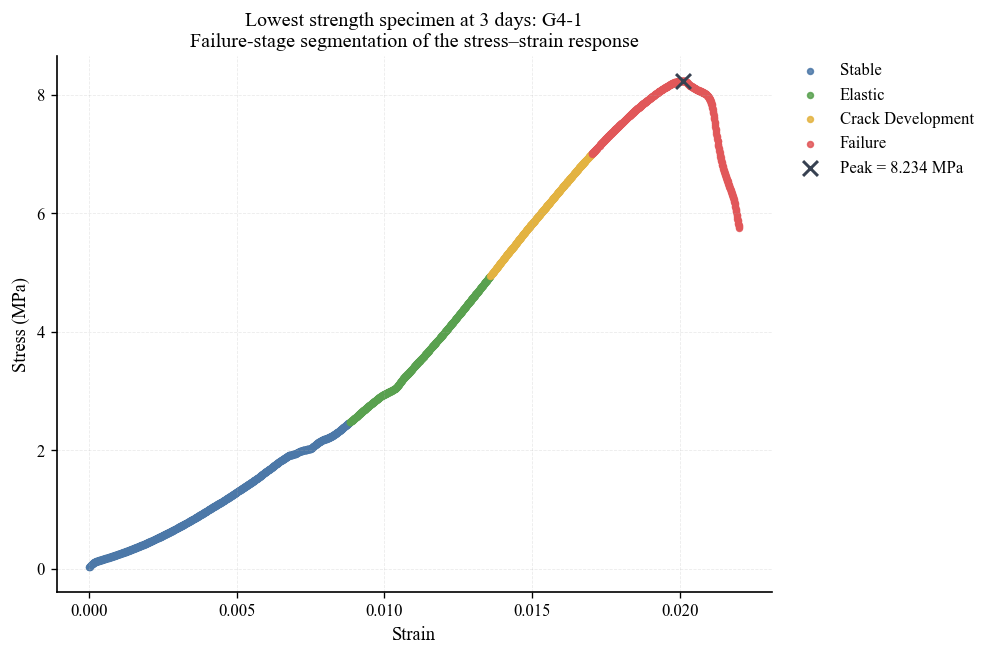

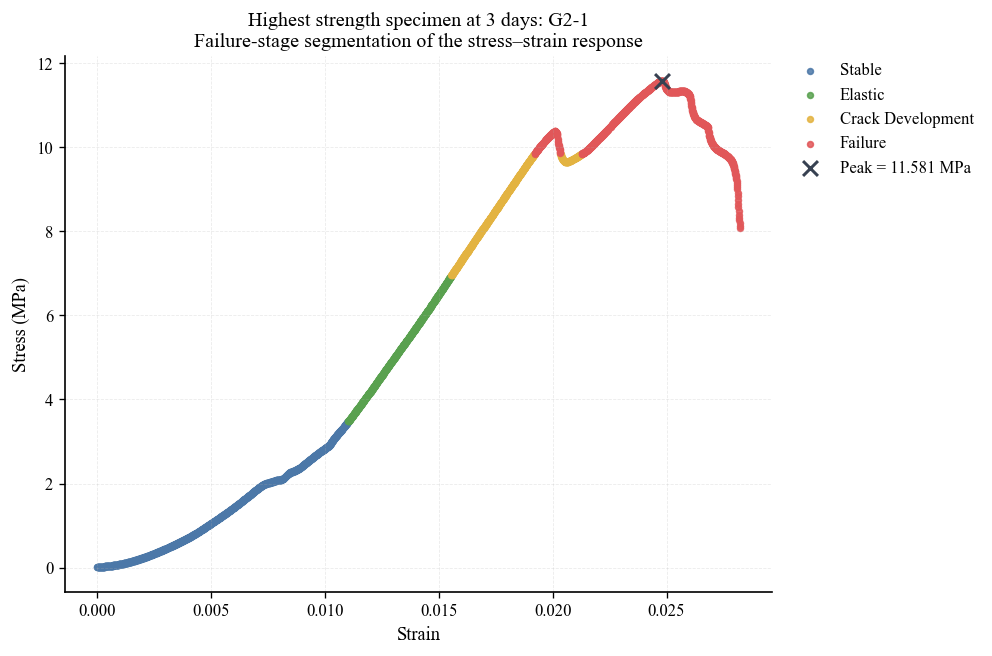

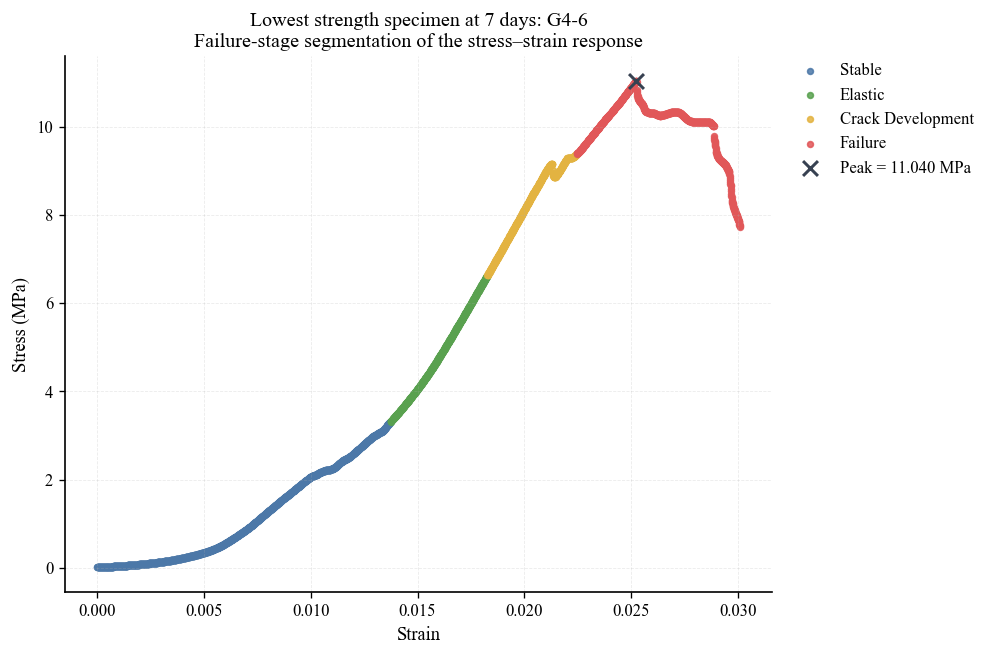

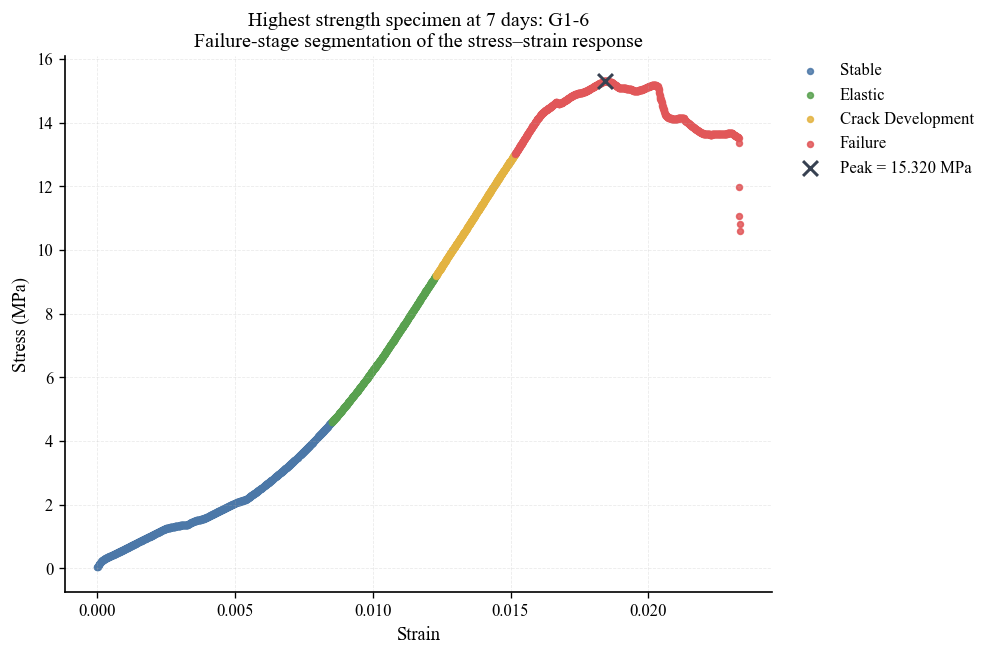

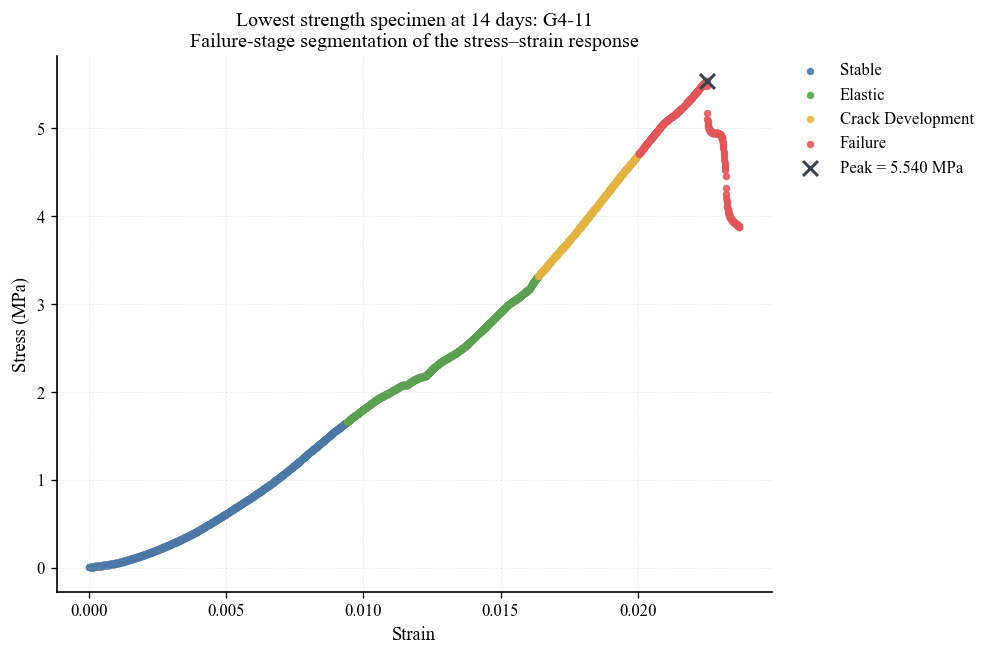

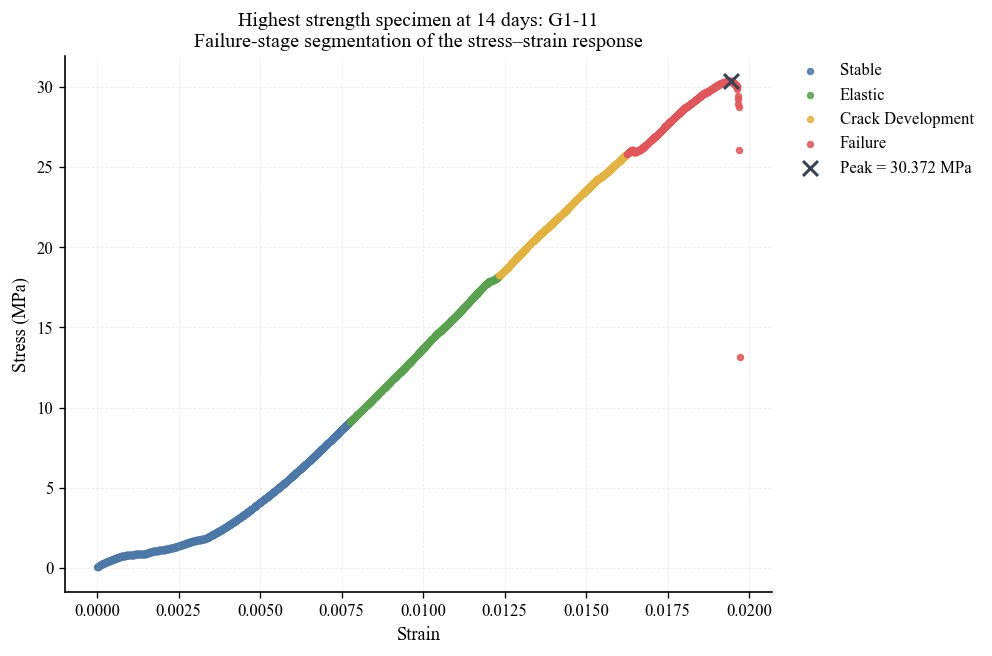

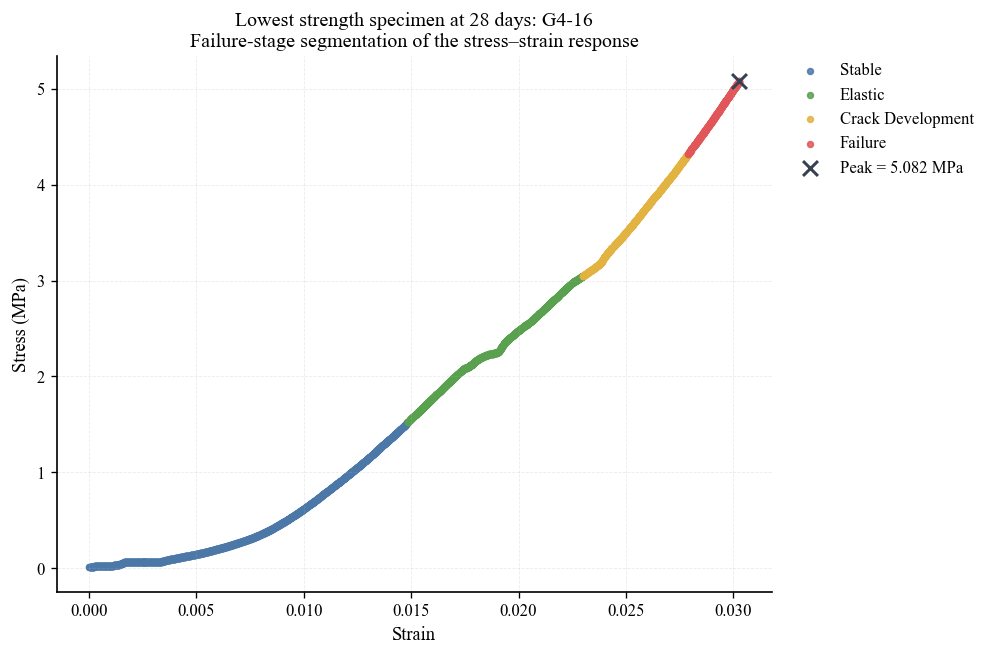

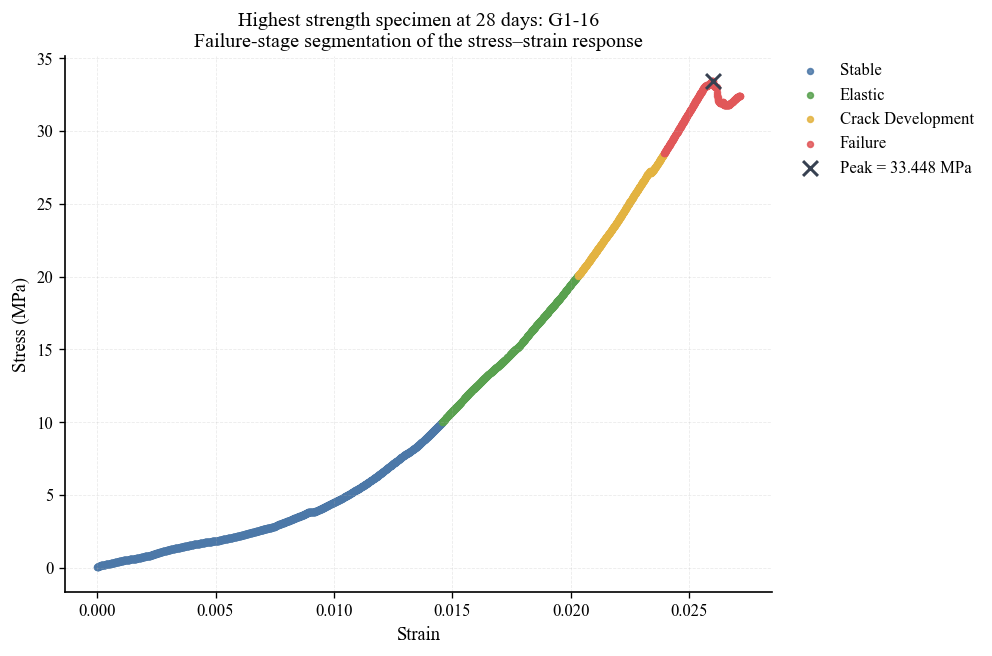

In [16]:
# ============================================================
# 16. Stage-labelled stress–strain curves
# ============================================================

for curing_day in sorted(representative_table["Curing_Days"].unique()):
    for strength_class in ["Lowest strength", "Highest strength"]:
        sample_id, sample = get_representative_sample(
            curing_day,
            strength_class
        )
        if sample is None:
            continue

        fig, ax = plt.subplots(figsize=(8.4, 5.6))

        for stage_name in STAGE_ORDER:
            stage_data = sample.loc[
                sample["Failure_Stage"].astype(str) == stage_name
            ]

            ax.scatter(
                stage_data["Strain"],
                stage_data["Stress_MPa"],
                s=12,
                color=STAGE_COLORS[stage_name],
                alpha=0.85,
                label=stage_name
            )

        peak_row = sample.loc[sample["Is_Peak_Row"]].iloc[0]

        ax.scatter(
            peak_row["Strain"],
            peak_row["Stress_MPa"],
            color=ACADEMIC_COLORS["dark_grey"],
            marker="x",
            s=80,
            linewidths=1.8,
            label=f"Peak = {peak_row['Stress_MPa']:.3f} MPa",
            zorder=6
        )

        ax.set_xlabel("Strain")
        ax.set_ylabel("Stress (MPa)")
        ax.set_title(
            f"{strength_class} specimen at {curing_day:g} days: {sample_id}\n"
            "Failure-stage segmentation of the stress–strain response"
        )

        format_academic_axis(ax)
        ax.legend(
            frameon=False,
            loc="upper left",
            bbox_to_anchor=(1.02, 1.0),
            borderaxespad=0.0
        )

        safe_class = strength_class.lower().replace(" ", "_")
        save_figure(
            fig,
            f"Figure_16_stage_stress_strain_{curing_day:g}d_{safe_class}_{sample_id}"
        )
        plt.show()


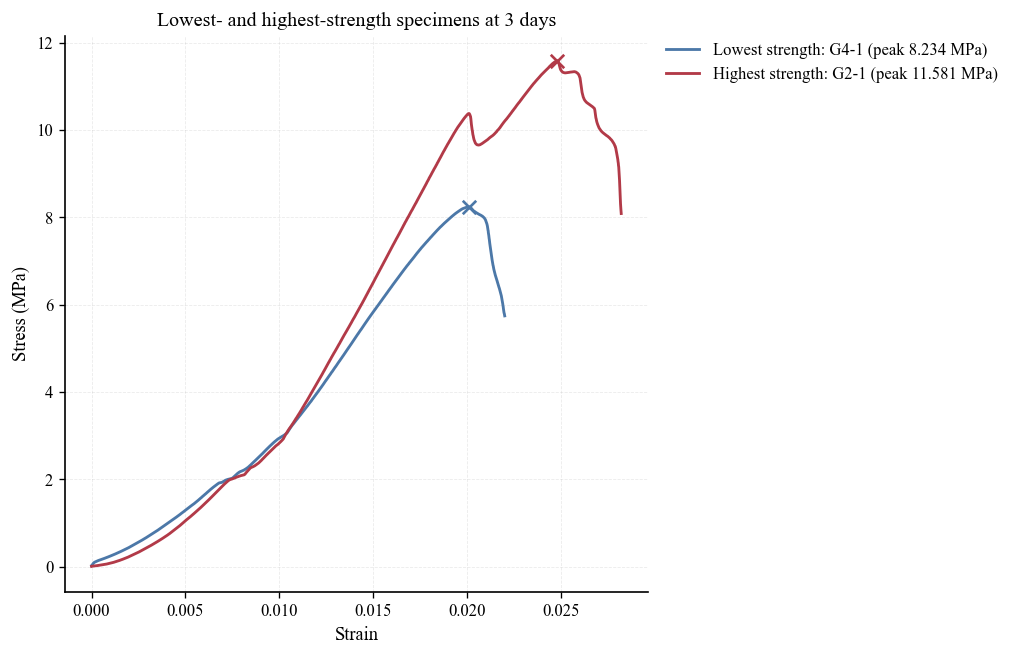

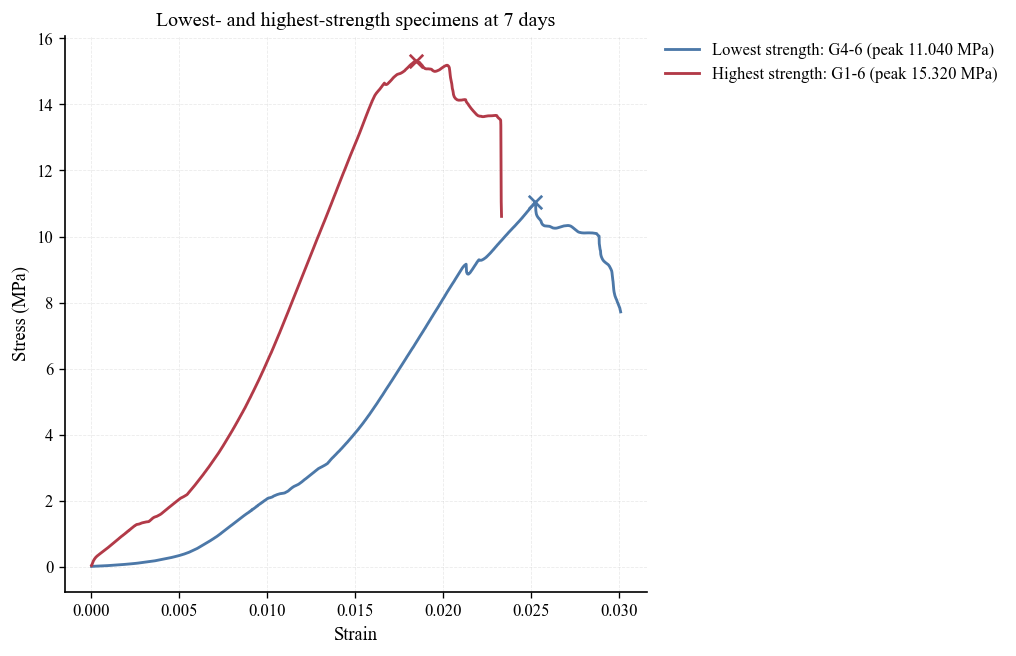

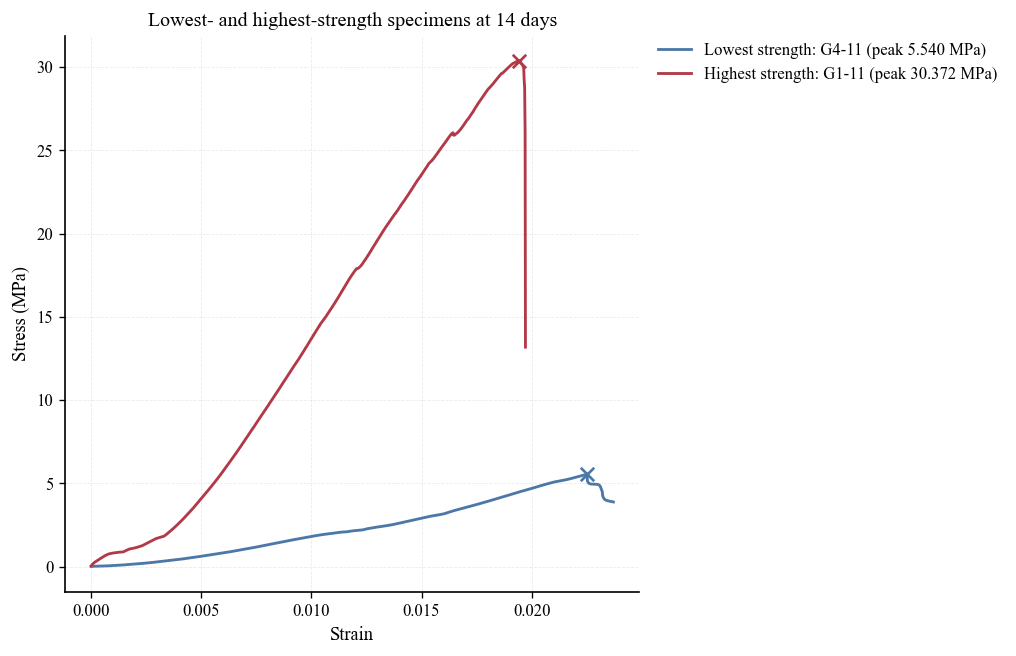

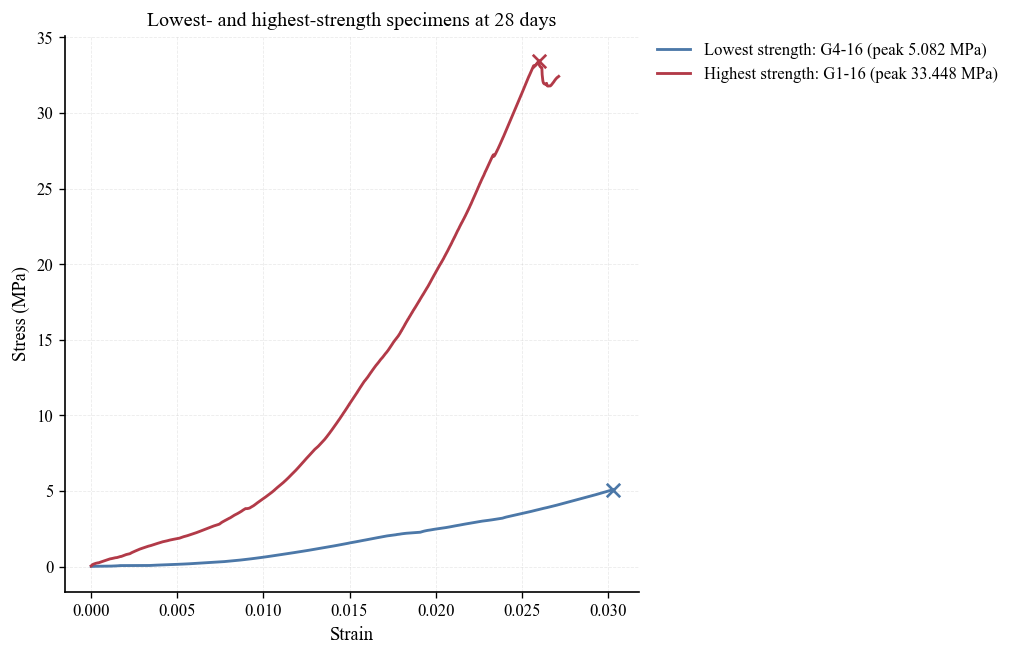

In [17]:
# ============================================================
# 17. Lowest- versus highest-strength stress–strain comparison
# ============================================================

for curing_day in sorted(representative_table["Curing_Days"].unique()):
    fig, ax = plt.subplots(figsize=(8.6, 5.6))

    for strength_class in ["Lowest strength", "Highest strength"]:
        sample_id, sample = get_representative_sample(
            curing_day,
            strength_class
        )
        if sample is None:
            continue

        ax.plot(
            sample["Strain"],
            sample["Stress_MPa"],
            color=STRENGTH_COLORS[strength_class],
            linewidth=1.7,
            label=(
                f"{strength_class}: {sample_id} "
                f"(peak {sample['Peak_Stress_MPa'].iloc[0]:.3f} MPa)"
            )
        )

        peak_row = sample.loc[sample["Is_Peak_Row"]].iloc[0]
        ax.scatter(
            peak_row["Strain"],
            peak_row["Stress_MPa"],
            color=STRENGTH_COLORS[strength_class],
            marker="x",
            s=65,
            linewidths=1.6,
            zorder=5
        )

    ax.set_xlabel("Strain")
    ax.set_ylabel("Stress (MPa)")
    ax.set_title(
        f"Lowest- and highest-strength specimens at {curing_day:g} days"
    )

    format_academic_axis(ax)
    ax.legend(
        frameon=False,
        loc="upper left",
        bbox_to_anchor=(1.02, 1.0),
        borderaxespad=0.0
    )

    save_figure(
        fig,
        f"Figure_17_lowest_highest_stress_strain_{curing_day:g}d"
    )
    plt.show()


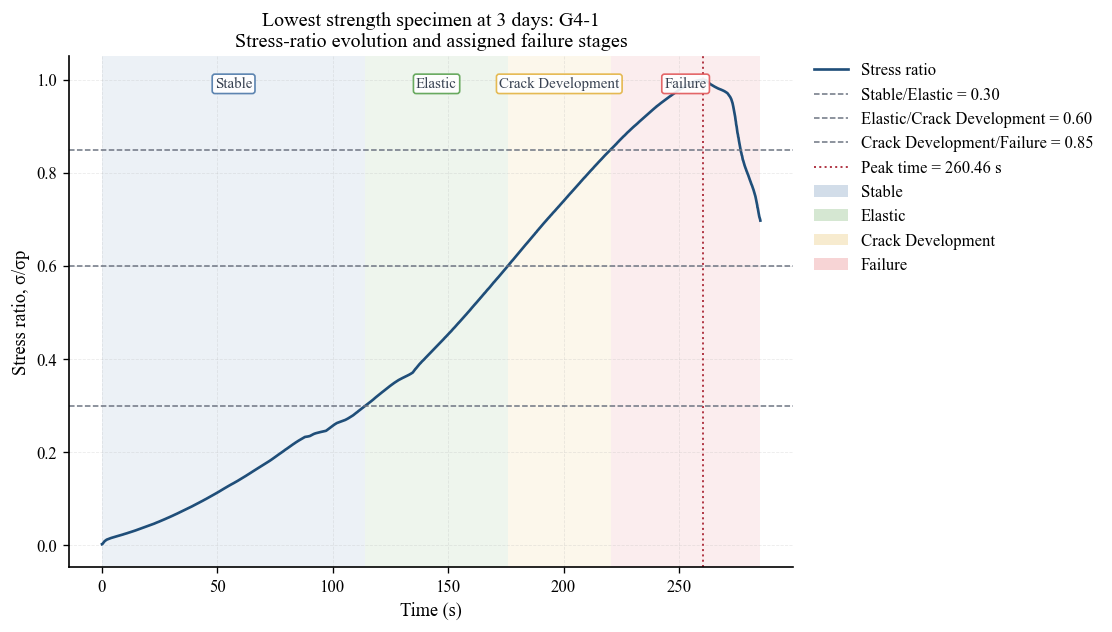

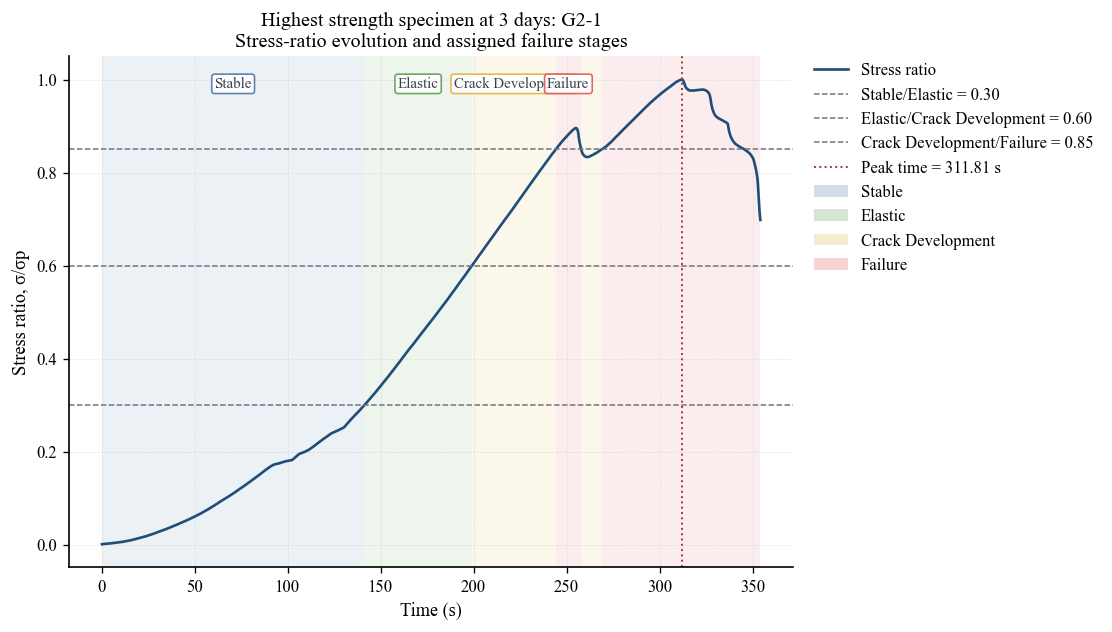

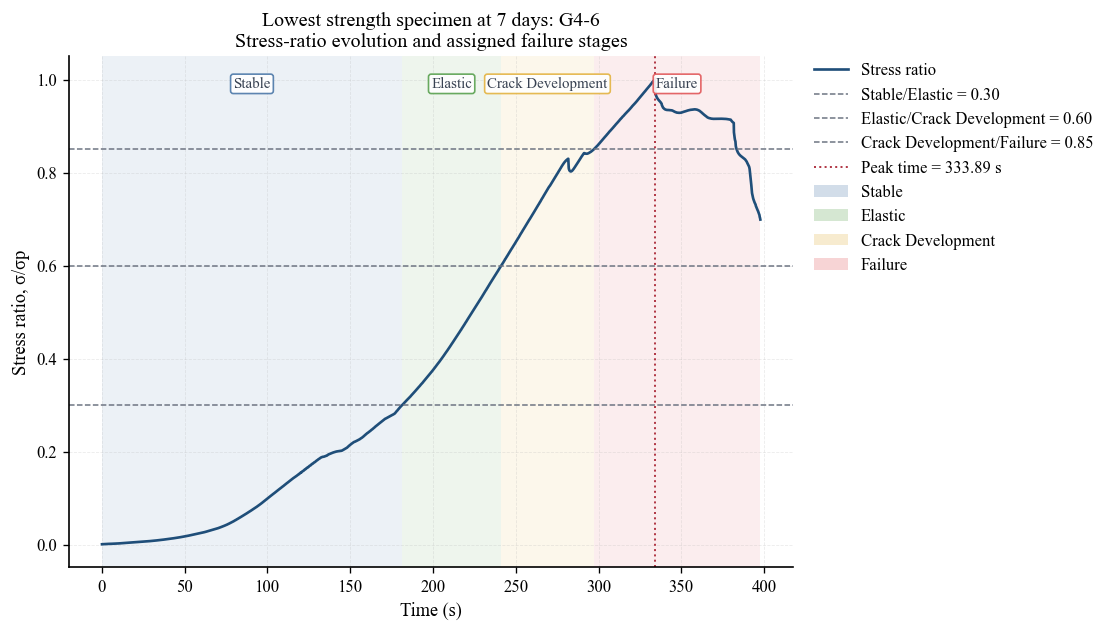

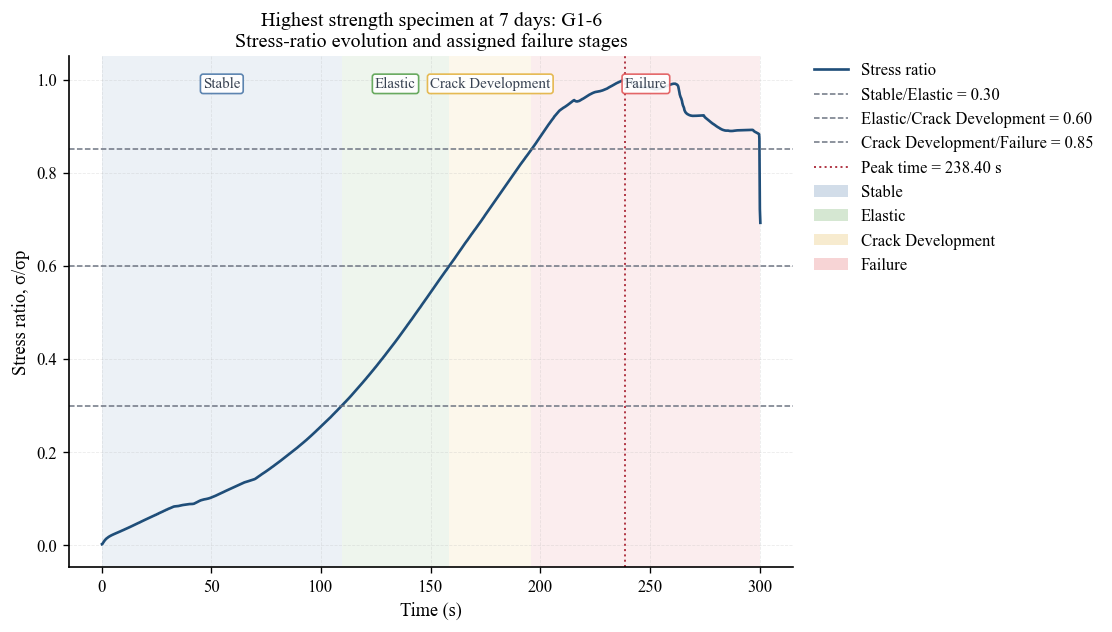

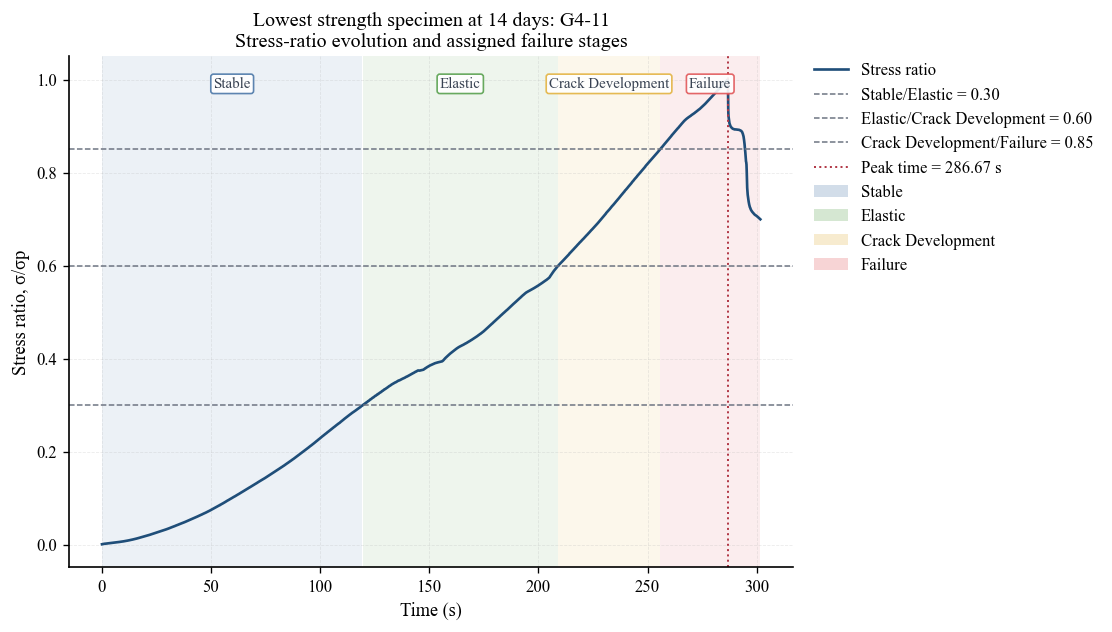

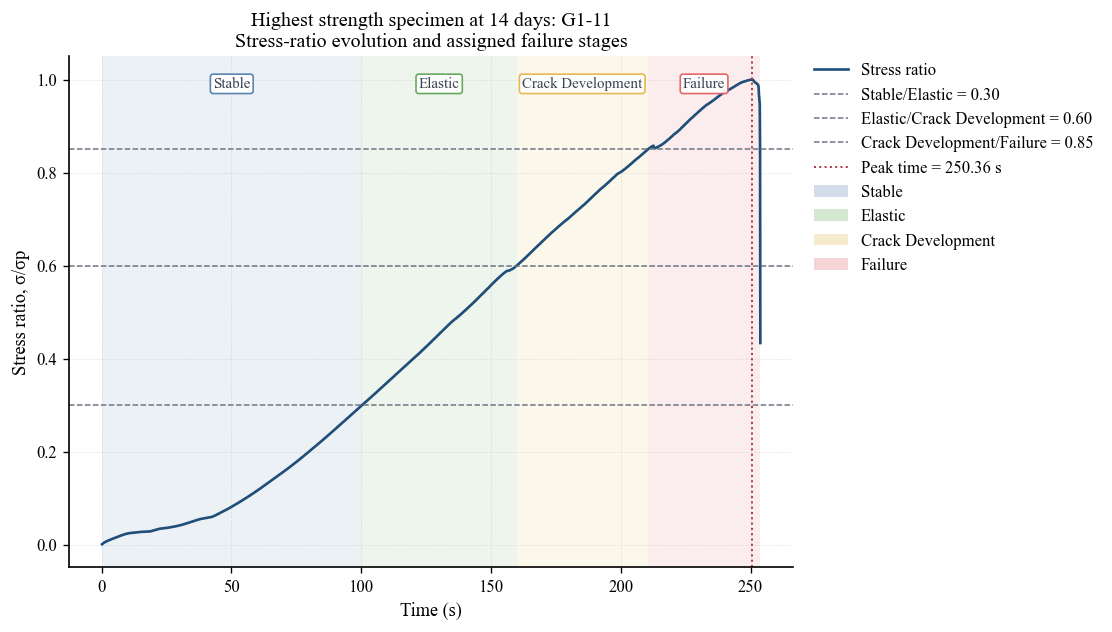

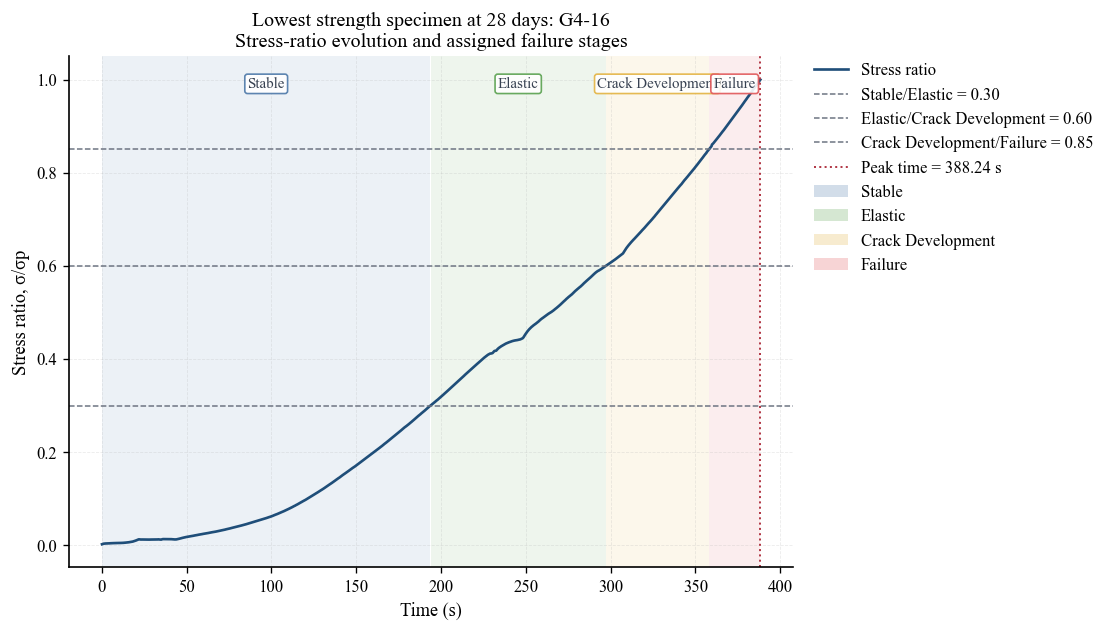

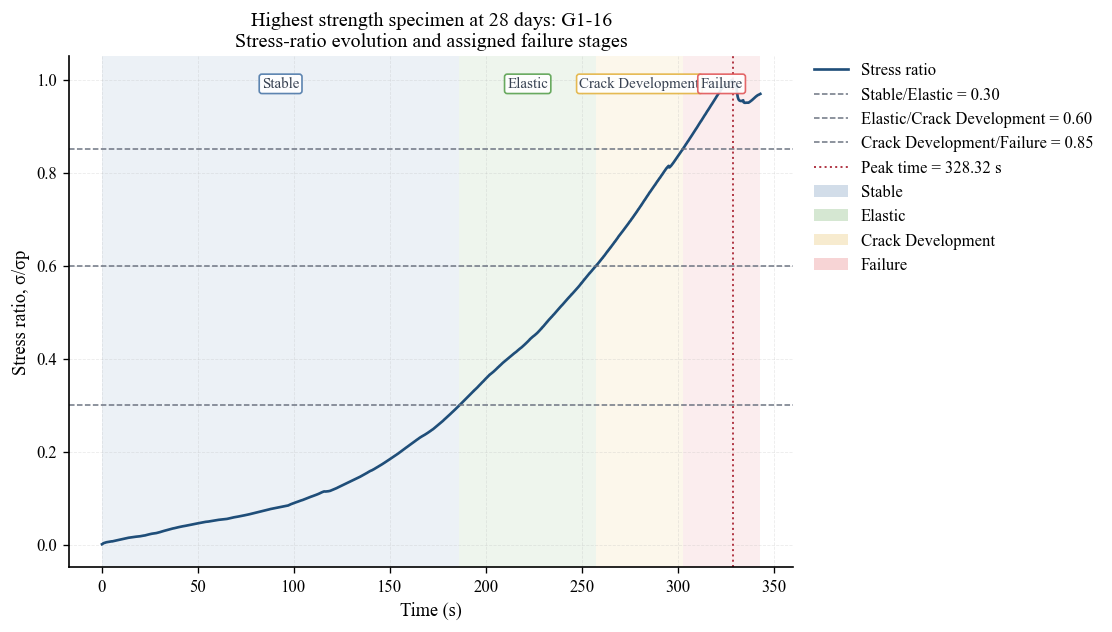

In [18]:
# ============================================================
# 18. Stress-ratio evolution with stage boundaries
# ============================================================

for curing_day in sorted(representative_table["Curing_Days"].unique()):
    for strength_class in ["Lowest strength", "Highest strength"]:
        sample_id, sample = get_representative_sample(
            curing_day,
            strength_class
        )
        if sample is None:
            continue

        fig, ax = plt.subplots(figsize=(9.4, 5.4))

        ax.plot(
            sample["Time_s"],
            sample["Stress_Ratio"],
            color=ACADEMIC_COLORS["navy"],
            linewidth=1.6,
            label="Stress ratio"
        )

        boundary_specs = [
            (STABLE_UPPER, "Stable/Elastic"),
            (ELASTIC_UPPER, "Elastic/Crack Development"),
            (CRACK_UPPER, "Crack Development/Failure")
        ]

        for value, label in boundary_specs:
            ax.axhline(
                value,
                color=ACADEMIC_COLORS["grey"],
                linestyle="--",
                linewidth=0.9,
                label=f"{label} = {value:.2f}"
            )

        peak_time = float(sample["Peak_Time_s"].iloc[0])
        ax.axvline(
            peak_time,
            color=ACADEMIC_COLORS["red"],
            linestyle=":",
            linewidth=1.2,
            label=f"Peak time = {peak_time:.2f} s"
        )

        ax.set_xlabel("Time (s)")
        ax.set_ylabel("Stress ratio, σ/σp")
        ax.set_title(
            f"{strength_class} specimen at {curing_day:g} days: {sample_id}\n"
            "Stress-ratio evolution and assigned failure stages"
        )

        format_academic_axis(ax)
        current_ylim = ax.get_ylim()
        add_failure_stage_regions(ax, sample, show_stage_labels=True)
        ax.set_ylim(current_ylim)
        add_stage_legend(ax)

        safe_class = strength_class.lower().replace(" ", "_")
        save_figure(
            fig,
            f"Figure_18_stress_ratio_{curing_day:g}d_{safe_class}_{sample_id}"
        )
        plt.show()


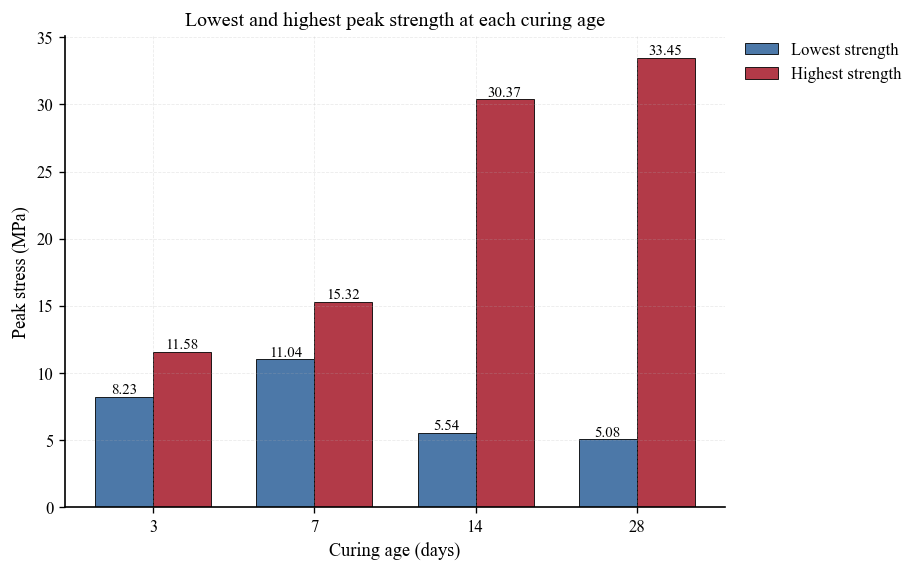

In [19]:
# ============================================================
# 19. Peak-strength range by curing age
# ============================================================

strength_summary_plot = representative_table.pivot(
    index="Curing_Days",
    columns="Strength_Class",
    values="Peak_Stress_MPa"
).reset_index()

fig, ax = plt.subplots(figsize=(7.8, 4.9))

x = np.arange(len(strength_summary_plot))
width = 0.36

low_values = strength_summary_plot["Lowest strength"]
high_values = strength_summary_plot["Highest strength"]

bars_low = ax.bar(
    x - width / 2,
    low_values,
    width,
    color=STRENGTH_COLORS["Lowest strength"],
    edgecolor="black",
    linewidth=0.5,
    label="Lowest strength"
)
bars_high = ax.bar(
    x + width / 2,
    high_values,
    width,
    color=STRENGTH_COLORS["Highest strength"],
    edgecolor="black",
    linewidth=0.5,
    label="Highest strength"
)

ax.set_xticks(x)
ax.set_xticklabels(
    [f"{day:g}" for day in strength_summary_plot["Curing_Days"]]
)
ax.set_xlabel("Curing age (days)")
ax.set_ylabel("Peak stress (MPa)")
ax.set_title("Lowest and highest peak strength at each curing age")

format_academic_axis(ax)
ax.legend(
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    borderaxespad=0.0
)

for bars in [bars_low, bars_high]:
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{bar.get_height():.2f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

save_figure(fig, "Figure_19_peak_strength_range_by_curing_age")
plt.show()


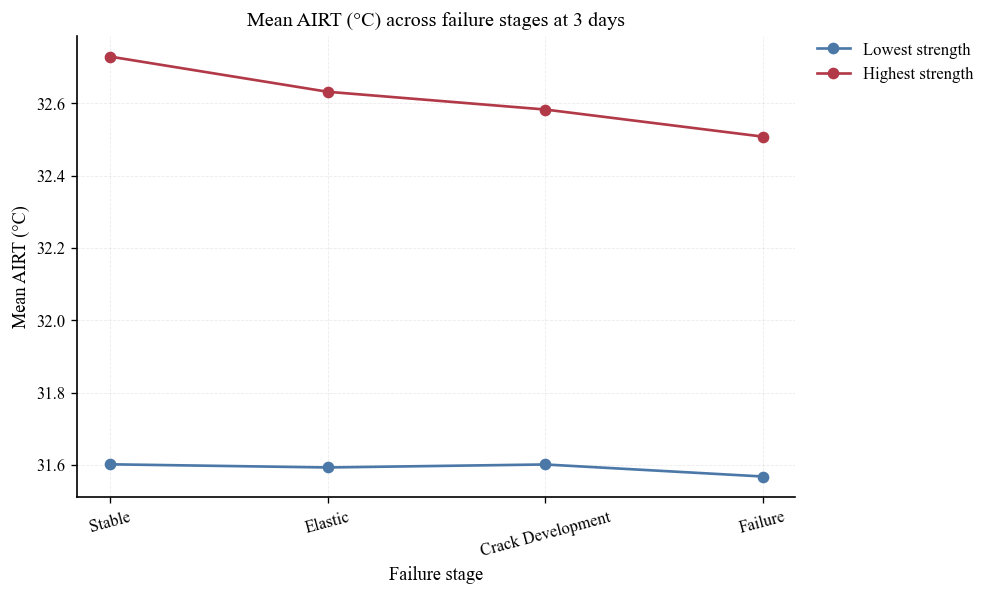

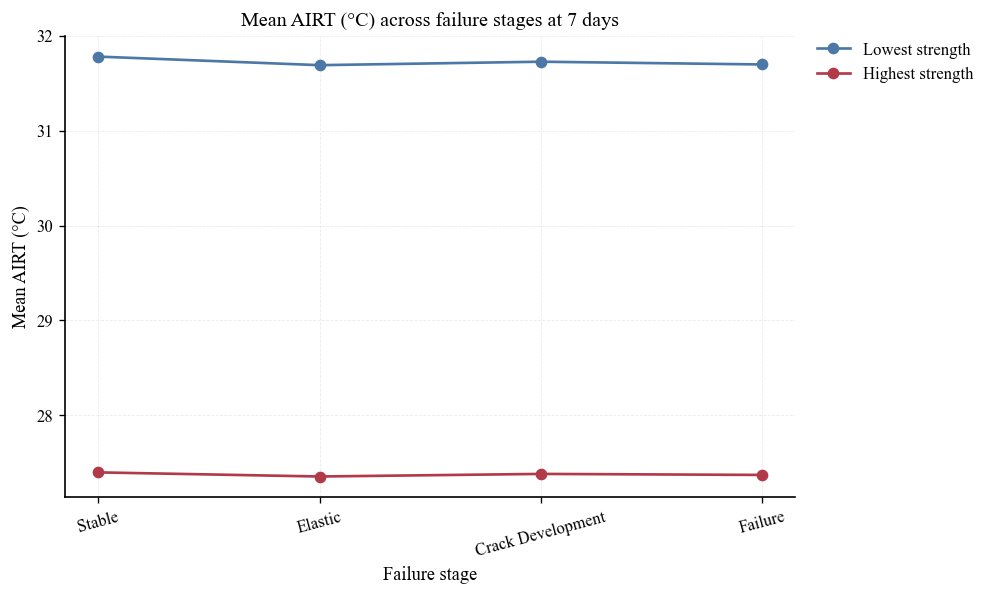

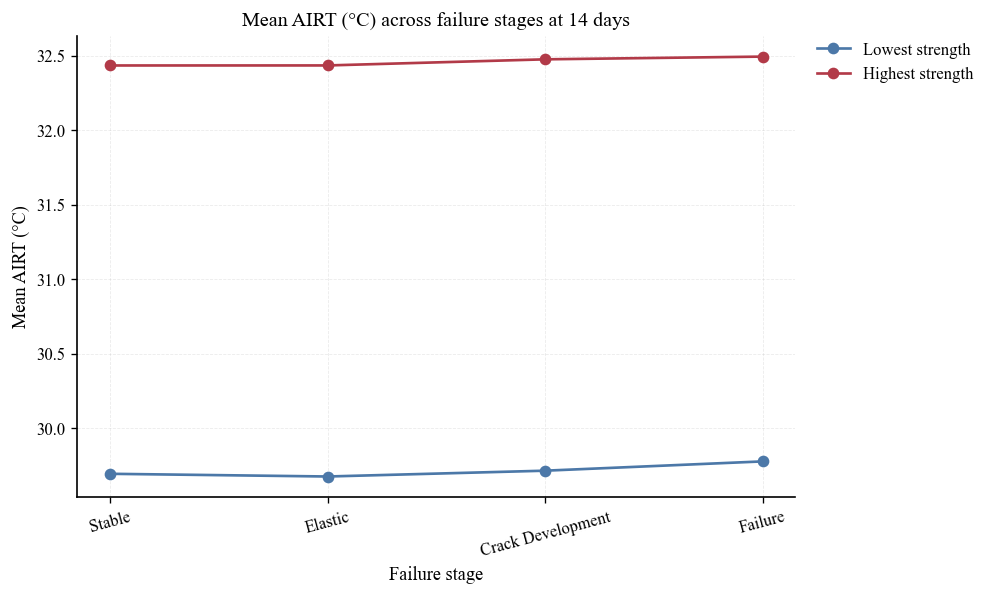

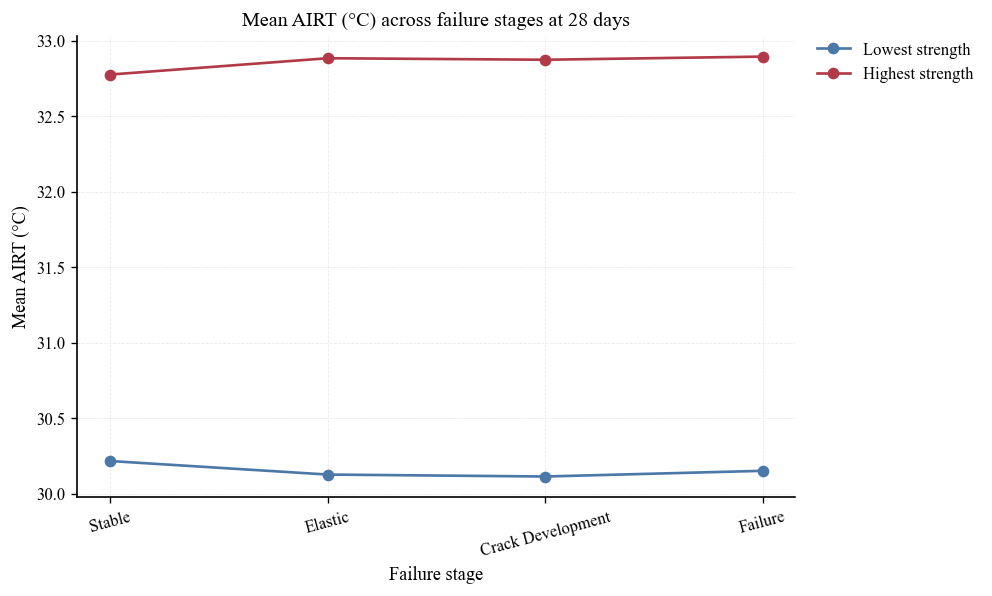

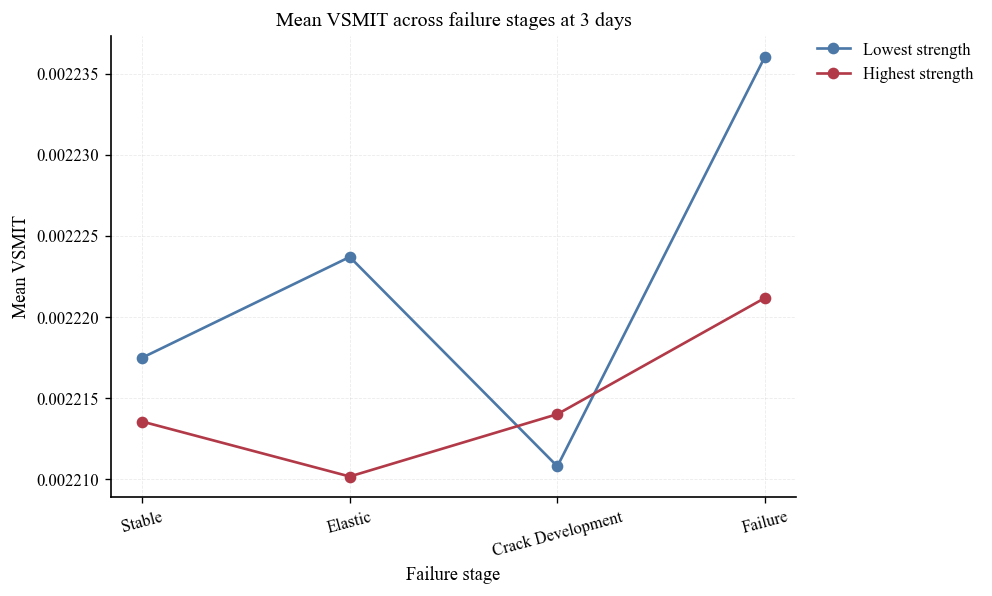

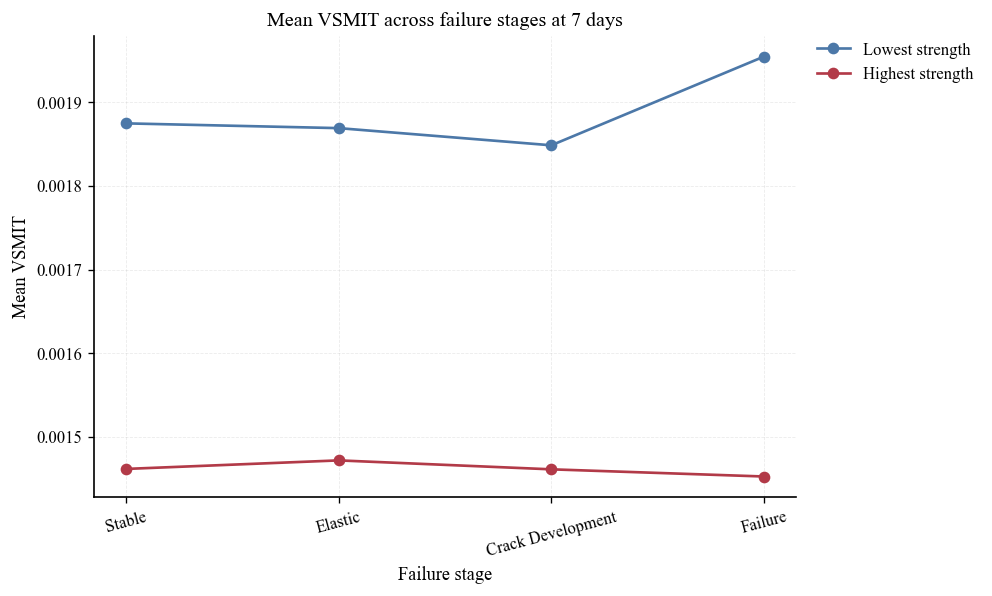

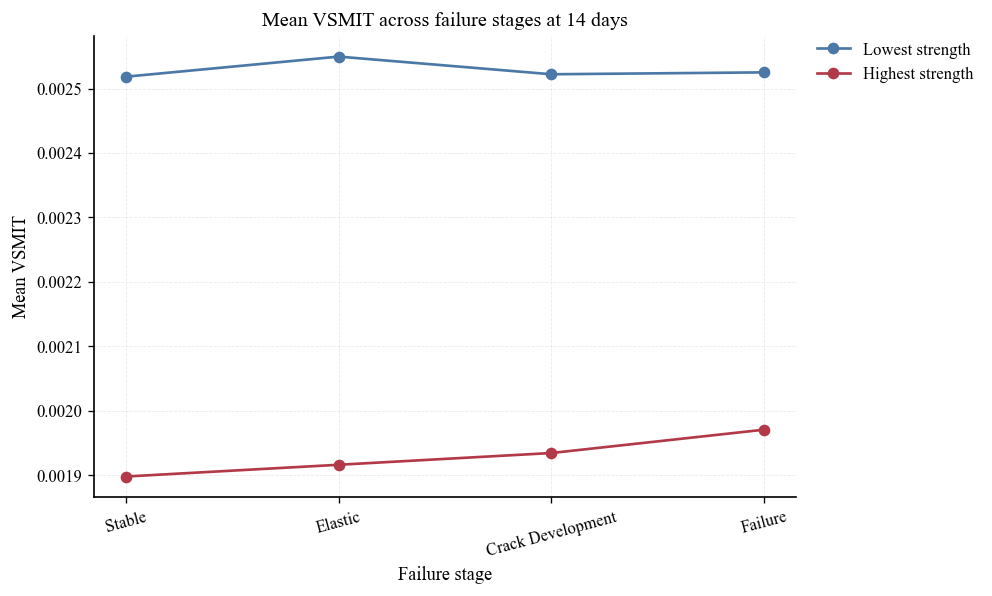

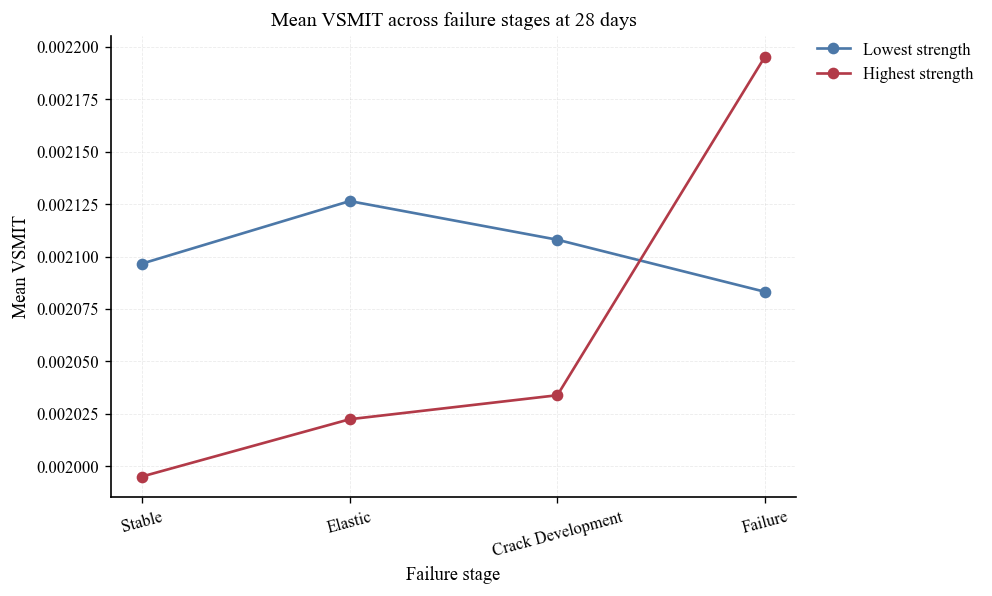

In [20]:
# ============================================================
# 20. Stage-wise AIRT and VSMIT summaries
# ============================================================

representative_stage_summary = (
    labelled.loc[
        labelled["Sample_ID"].isin(representative_ids)
    ]
    .merge(
        representative_table[
            ["Sample_ID", "Curing_Days", "Strength_Class"]
        ],
        on="Sample_ID",
        how="left"
    )
    .groupby(
        ["Curing_Days", "Strength_Class", "Failure_Stage"],
        observed=False
    )
    .agg(
        Mean_AIRT_C=("AIRT_C", "mean"),
        Mean_VSMIT=("VSMIT", "mean"),
        Mean_Stress_MPa=("Stress_MPa", "mean"),
        Mean_Strain=("Strain", "mean"),
        Observations=("Sample_ID", "size")
    )
    .reset_index()
)

for metric, ylabel, color_key, figure_no in [
    ("Mean_AIRT_C", "Mean AIRT (°C)", "teal", 20),
    ("Mean_VSMIT", "Mean VSMIT", "orange", 21)
]:
    for curing_day in sorted(
        representative_stage_summary["Curing_Days"].dropna().unique()
    ):
        fig, ax = plt.subplots(figsize=(8.4, 5.1))

        for strength_class in ["Lowest strength", "Highest strength"]:
            subset = (
                representative_stage_summary.loc[
                    (representative_stage_summary["Curing_Days"] == curing_day) &
                    (representative_stage_summary["Strength_Class"] == strength_class)
                ]
                .set_index("Failure_Stage")
                .reindex(STAGE_ORDER)
                .reset_index()
            )

            ax.plot(
                subset["Failure_Stage"].astype(str),
                subset[metric],
                marker="o",
                linewidth=1.6,
                color=STRENGTH_COLORS[strength_class],
                label=strength_class
            )

        ax.set_xlabel("Failure stage")
        ax.set_ylabel(ylabel)
        ax.set_title(
            f"{ylabel} across failure stages at {curing_day:g} days"
        )

        format_academic_axis(ax)
        ax.legend(
            frameon=False,
            loc="upper left",
            bbox_to_anchor=(1.02, 1.0),
            borderaxespad=0.0
        )
        plt.xticks(rotation=15)

        save_figure(
            fig,
            f"Figure_{figure_no}_{metric}_{curing_day:g}d"
        )
        plt.show()


In [21]:
# ============================================================
# 11. Helper functions for explanatory dual-axis figures
# ============================================================

STAGE_BOUNDARIES = {
    "Stable/Elastic": STABLE_UPPER,
    "Elastic/Crack Development": ELASTIC_UPPER,
    "Crack Development/Failure": CRACK_UPPER
}

def add_stage_background(axis, sample):
    """
    Shades contiguous failure-stage intervals on a time-based axis.
    """
    stage_series = sample["Failure_Stage"].astype(str)
    segment_id = stage_series.ne(stage_series.shift()).cumsum()

    for _, segment in sample.groupby(segment_id):
        axis.axvspan(
            segment["Time_s"].min(),
            segment["Time_s"].max(),
            alpha=0.07
        )

def mark_peak(axis, sample):
    peak_time = float(sample["Peak_Time_s"].iloc[0])
    axis.axvline(
        peak_time,
        linestyle=":",
        linewidth=1.3,
        label=f"Peak time = {peak_time:.2f} s"
    )

def combine_legends(axis_left, axis_right, location="best"):
    handles_left, labels_left = axis_left.get_legend_handles_labels()
    handles_right, labels_right = axis_right.get_legend_handles_labels()

    unique = {}
    for handle, label in zip(
        handles_left + handles_right,
        labels_left + labels_right
    ):
        if label and label not in unique:
            unique[label] = handle

    axis_left.legend(
        unique.values(),
        unique.keys(),
        frameon=False,
        loc=location
    )

def get_representative_sample(curing_day, strength_class):
    row = representative_table.loc[
        (representative_table["Curing_Days"] == curing_day) &
        (representative_table["Strength_Class"] == strength_class)
    ]

    if row.empty:
        return None, None

    sample_id = row["Sample_ID"].iloc[0]
    sample = (
        labelled.loc[labelled["Sample_ID"] == sample_id]
        .sort_values("Time_s")
        .copy()
    )
    return sample_id, sample


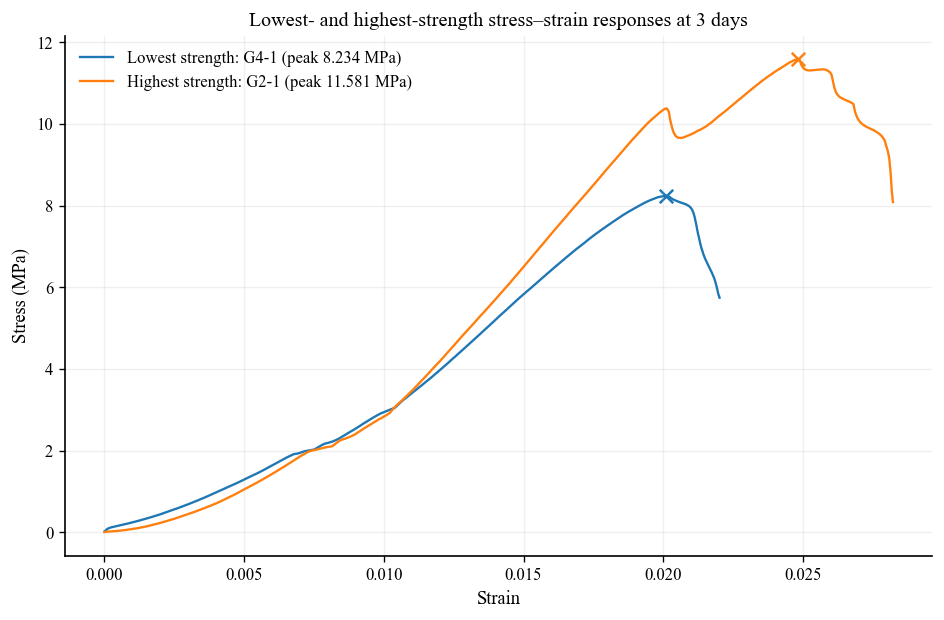

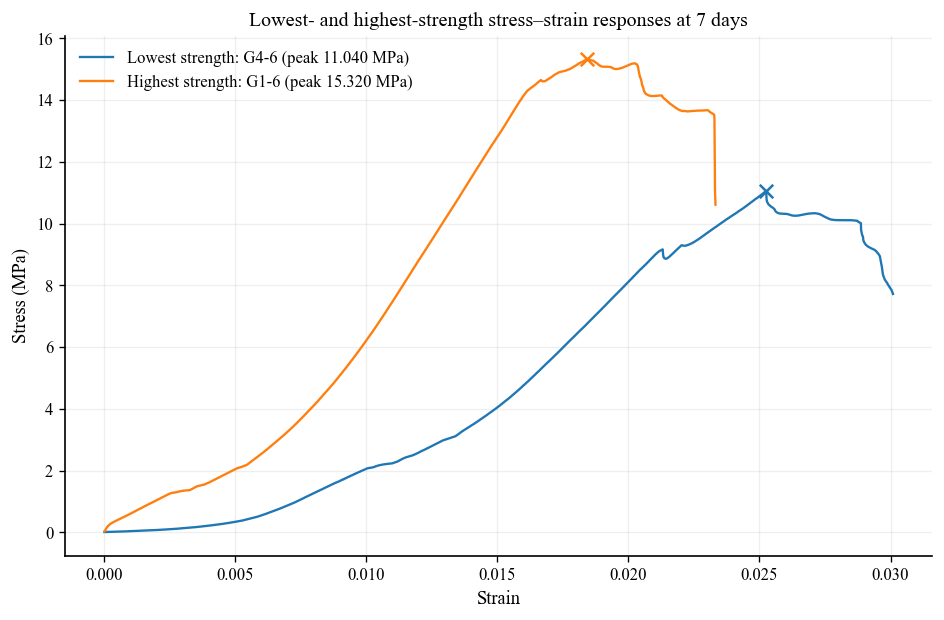

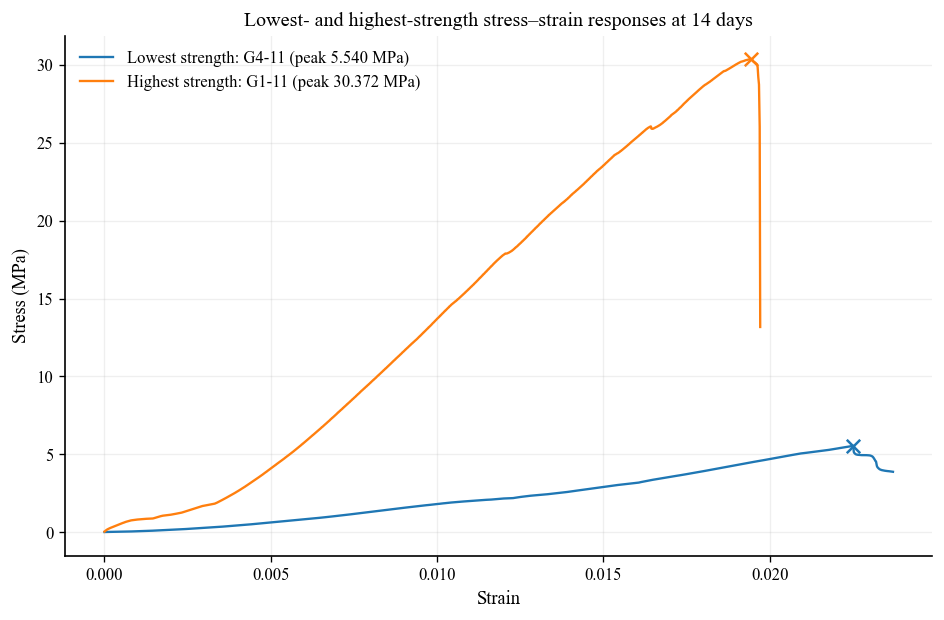

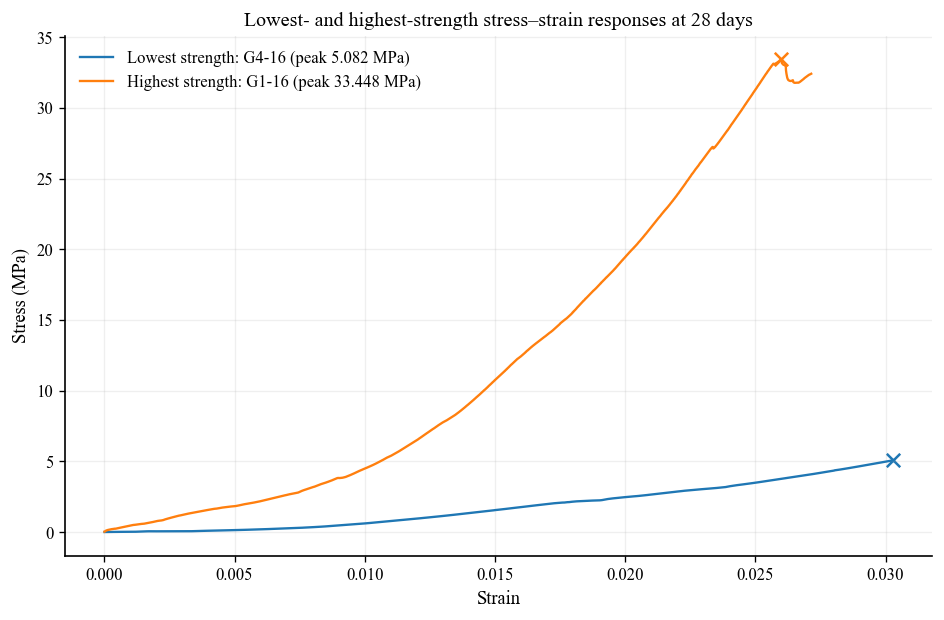

In [22]:
# ============================================================
# 15. Figure 5 — Stress–strain curves comparing lowest and highest
#     strength specimens at each curing day
# ============================================================

for curing_day in sorted(representative_table["Curing_Days"].unique()):
    fig, ax = plt.subplots(figsize=(8.0, 5.3))

    for strength_class in ["Lowest strength", "Highest strength"]:
        sample_id, sample = get_representative_sample(
            curing_day,
            strength_class
        )
        if sample is None:
            continue

        ax.plot(
            sample["Strain"],
            sample["Stress_MPa"],
            label=(
                f"{strength_class}: {sample_id} "
                f"(peak {sample['Peak_Stress_MPa'].iloc[0]:.3f} MPa)"
            )
        )

        peak_row = sample.loc[sample["Is_Peak_Row"]].iloc[0]
        ax.scatter(
            peak_row["Strain"],
            peak_row["Stress_MPa"],
            marker="x",
            s=65,
            linewidths=1.5
        )

    ax.set_xlabel("Strain")
    ax.set_ylabel("Stress (MPa)")
    ax.set_title(
        f"Lowest- and highest-strength stress–strain responses "
        f"at {curing_day:g} days"
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)

    fig.savefig(
        FIGURE_DIR /
        f"Figure_05_lowest_highest_stress_strain_{curing_day:g}d.png",
        bbox_inches="tight"
    )
    fig.savefig(
        FIGURE_DIR /
        f"Figure_05_lowest_highest_stress_strain_{curing_day:g}d.tiff",
        bbox_inches="tight"
    )
    plt.show()


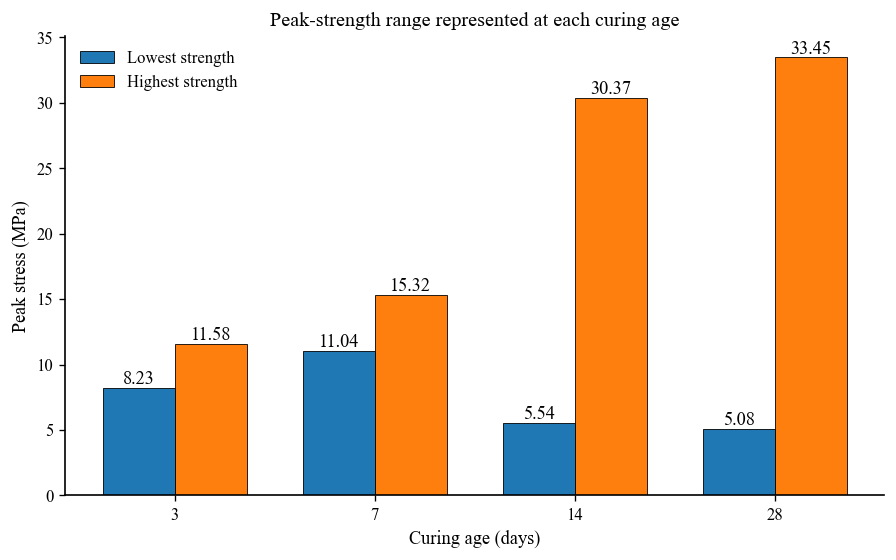

In [23]:
# ============================================================
# 16. Figure 6 — Peak-strength contrast by curing day
# ============================================================

strength_contrast = representative_table.pivot(
    index="Curing_Days",
    columns="Strength_Class",
    values="Peak_Stress_MPa"
).reset_index()

fig, ax = plt.subplots(figsize=(7.6, 4.8))

x = np.arange(len(strength_contrast))
width = 0.36

lowest_values = strength_contrast.get(
    "Lowest strength",
    pd.Series(np.nan, index=strength_contrast.index)
)
highest_values = strength_contrast.get(
    "Highest strength",
    pd.Series(np.nan, index=strength_contrast.index)
)

ax.bar(
    x - width/2,
    lowest_values,
    width,
    label="Lowest strength",
    edgecolor="black",
    linewidth=0.5
)
ax.bar(
    x + width/2,
    highest_values,
    width,
    label="Highest strength",
    edgecolor="black",
    linewidth=0.5
)

ax.set_xticks(x)
ax.set_xticklabels(
    [f"{day:g}" for day in strength_contrast["Curing_Days"]]
)
ax.set_xlabel("Curing age (days)")
ax.set_ylabel("Peak stress (MPa)")
ax.set_title("Peak-strength range represented at each curing age")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)

for xpos, low, high in zip(x, lowest_values, highest_values):
    if np.isfinite(low):
        ax.text(xpos - width/2, low, f"{low:.2f}", ha="center", va="bottom")
    if np.isfinite(high):
        ax.text(xpos + width/2, high, f"{high:.2f}", ha="center", va="bottom")

fig.savefig(
    FIGURE_DIR / "Figure_06_peak_strength_range_by_curing_day.png",
    bbox_inches="tight"
)
fig.savefig(
    FIGURE_DIR / "Figure_06_peak_strength_range_by_curing_day.tiff",
    bbox_inches="tight"
)
plt.show()


In [24]:
# ============================================================
# 20. Export representative-sample summaries
# ============================================================

representative_stage_summary.to_csv(
    QC_DIR / "representative_stage_signal_summary.csv",
    index=False
)

with pd.ExcelWriter(
    OUTPUT_DIR / "representative_lowest_highest_by_curing_day.xlsx",
    engine="openpyxl"
) as writer:
    representative_table.to_excel(
        writer,
        sheet_name="Selected_Specimens",
        index=False
    )
    representative_stage_summary.to_excel(
        writer,
        sheet_name="Stage_Signal_Summary",
        index=False
    )

print(
    "Representative selection and stage summaries exported to:",
    OUTPUT_DIR / "representative_lowest_highest_by_curing_day.xlsx"
)


Representative selection and stage summaries exported to: C:\Users\Eddie\Desktop\new_exp_june\Project_Dir\failure_stage_outputs3\representative_lowest_highest_by_curing_day.xlsx


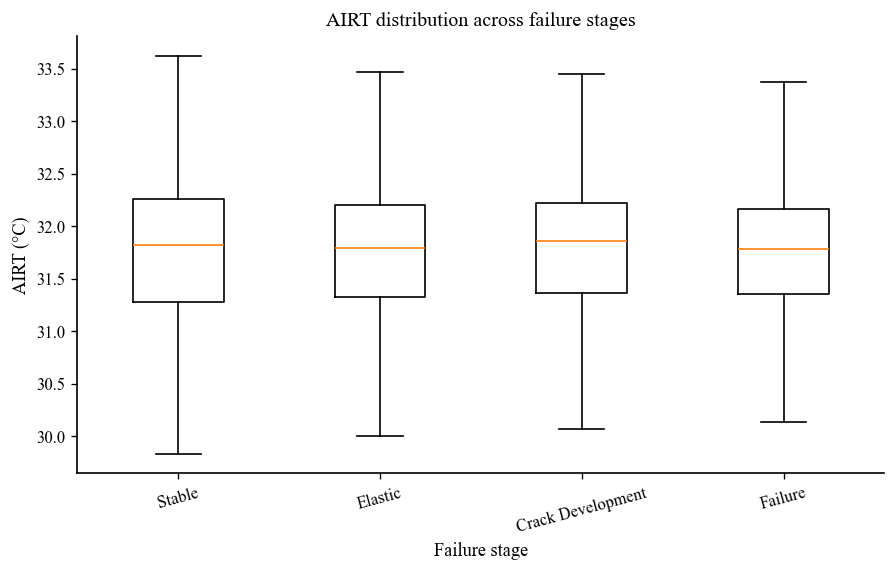

In [25]:
# ============================================================
# 13. Figure 4 — AIRT distribution by failure stage
# ============================================================

airt_by_stage = [
    labelled.loc[
        labelled["Failure_Stage"].astype(str) == stage,
        "AIRT_C"
    ].dropna().to_numpy()
    for stage in STAGE_ORDER
]

fig, ax = plt.subplots(figsize=(7.6, 4.9))

ax.boxplot(
    airt_by_stage,
    labels=STAGE_ORDER,
    showfliers=False
)

ax.set_xlabel("Failure stage")
ax.set_ylabel("AIRT (°C)")
ax.set_title("AIRT distribution across failure stages")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.xticks(rotation=15)

fig.savefig(
    FIGURE_DIR / "Figure_04_AIRT_by_failure_stage.png",
    bbox_inches="tight"
)
fig.savefig(
    FIGURE_DIR / "Figure_04_AIRT_by_failure_stage.tiff",
    bbox_inches="tight"
)
plt.show()


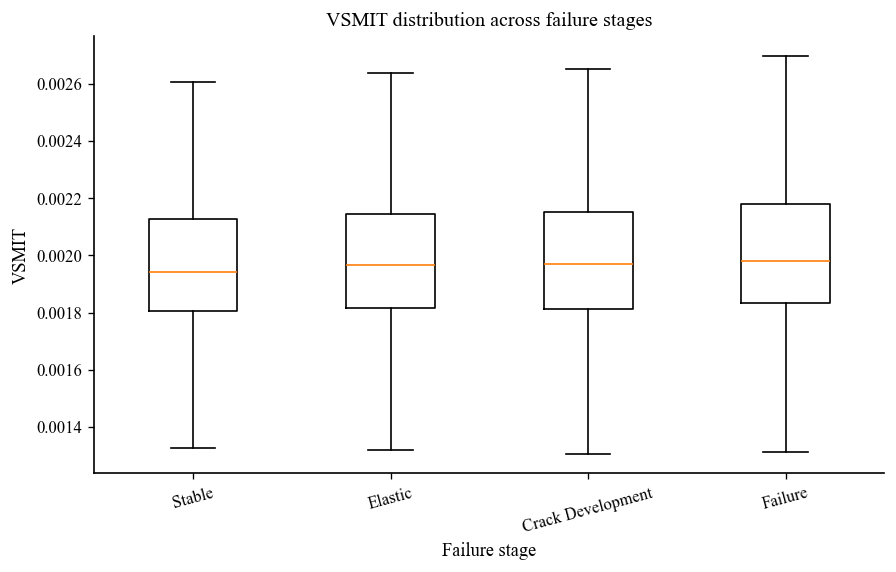

In [26]:
# ============================================================
# 14. Figure 5 — VSMIT distribution by failure stage
# ============================================================

vsmit_by_stage = [
    labelled.loc[
        labelled["Failure_Stage"].astype(str) == stage,
        "VSMIT"
    ].dropna().to_numpy()
    for stage in STAGE_ORDER
]

fig, ax = plt.subplots(figsize=(7.6, 4.9))

ax.boxplot(
    vsmit_by_stage,
    labels=STAGE_ORDER,
    showfliers=False
)

ax.set_xlabel("Failure stage")
ax.set_ylabel("VSMIT")
ax.set_title("VSMIT distribution across failure stages")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.xticks(rotation=15)

fig.savefig(
    FIGURE_DIR / "Figure_05_VSMIT_by_failure_stage.png",
    bbox_inches="tight"
)
fig.savefig(
    FIGURE_DIR / "Figure_05_VSMIT_by_failure_stage.tiff",
    bbox_inches="tight"
)
plt.show()


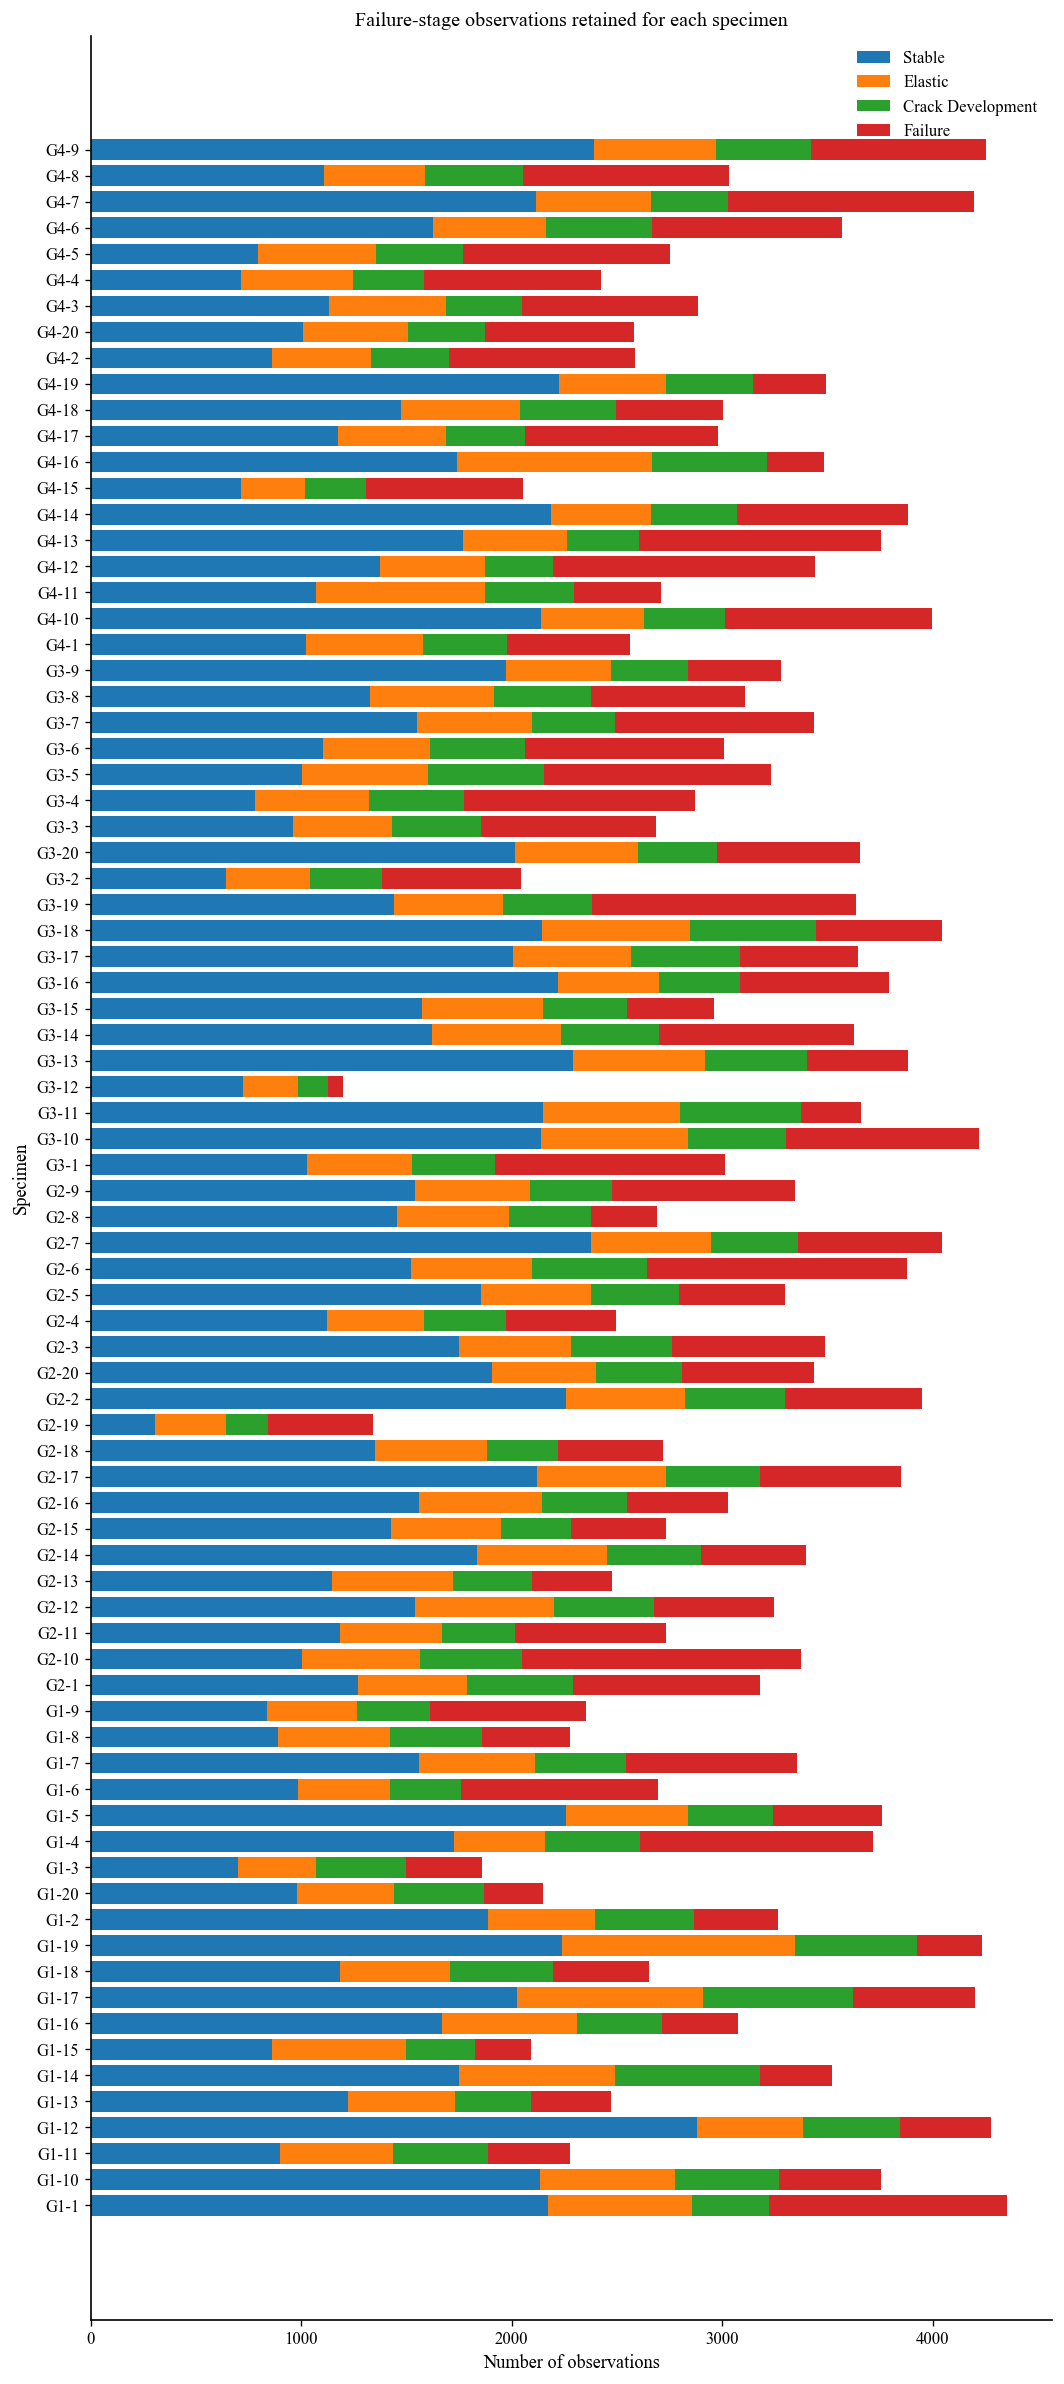

In [27]:
# ============================================================
# 16. Figure 7 — Stage counts for each specimen
# ============================================================

stage_count_plot = (
    labelled.groupby(
        ["Sample_ID", "Failure_Stage"],
        observed=False
    )
    .size()
    .unstack(fill_value=0)
    .reindex(columns=STAGE_ORDER, fill_value=0)
)

fig_height = max(7, 0.25 * len(stage_count_plot))

fig, ax = plt.subplots(
    figsize=(9.0, fig_height)
)

left = np.zeros(len(stage_count_plot))

for stage_name in STAGE_ORDER:
    values = stage_count_plot[stage_name].to_numpy()

    ax.barh(
        stage_count_plot.index,
        values,
        left=left,
        label=stage_name
    )

    left = left + values

ax.set_xlabel("Number of observations")
ax.set_ylabel("Specimen")
ax.set_title("Failure-stage observations retained for each specimen")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)

fig.savefig(
    FIGURE_DIR / "Figure_07_stage_counts_by_specimen.png",
    bbox_inches="tight"
)
fig.savefig(
    FIGURE_DIR / "Figure_07_stage_counts_by_specimen.tiff",
    bbox_inches="tight"
)
plt.show()


## Boundary-sensitivity dataset

To support later robustness testing, the next cell creates alternative stage labels using two additional boundary schemes. These are not used as the primary labels, but they make it possible to test whether model performance depends strongly on one arbitrary stage definition.


In [28]:
# ============================================================
# 17. Add alternative boundary schemes for sensitivity analysis
# ============================================================

def assign_stage_with_boundaries(
    stress_ratio,
    loading_branch,
    stable_upper,
    elastic_upper,
    crack_upper
):
    if loading_branch == "Peak/Post-Peak":
        return "Failure"

    if stress_ratio < stable_upper:
        return "Stable"
    if stress_ratio < elastic_upper:
        return "Elastic"
    if stress_ratio < crack_upper:
        return "Crack Development"
    return "Failure"

sensitivity_schemes = {
    "Stage_Scheme_25_50_80": (0.25, 0.50, 0.80),
    "Stage_Scheme_30_60_85": (0.30, 0.60, 0.85),
    "Stage_Scheme_35_65_90": (0.35, 0.65, 0.90)
}

for new_column, boundaries in sensitivity_schemes.items():
    labelled[new_column] = [
        assign_stage_with_boundaries(
            stress_ratio=ratio,
            loading_branch=branch,
            stable_upper=boundaries[0],
            elastic_upper=boundaries[1],
            crack_upper=boundaries[2]
        )
        for ratio, branch in zip(
            labelled["Stress_Ratio"],
            labelled["Loading_Branch"]
        )
    ]

display(
    labelled[
        [
            "Sample_ID",
            "Time_s",
            "Stress_Ratio",
            "Loading_Branch",
            "Failure_Stage",
            "Stage_Scheme_25_50_80",
            "Stage_Scheme_30_60_85",
            "Stage_Scheme_35_65_90"
        ]
    ].head(20)
)


,Sample_ID,Time_s,Stress_Ratio,Loading_Branch,Failure_Stage,Stage_Scheme_25_50_80,Stage_Scheme_30_60_85,Stage_Scheme_35_65_90
0,G1-1,0.109,0.000861,Pre-Peak,Stable,Stable,Stable,Stable
1,G1-1,0.218,0.000891,Pre-Peak,Stable,Stable,Stable,Stable
2,G1-1,0.343,0.000950,Pre-Peak,Stable,Stable,Stable,Stable
3,G1-1,0.452,0.000980,Pre-Peak,Stable,Stable,Stable,Stable
4,G1-1,0.561,0.000950,Pre-Peak,Stable,Stable,Stable,Stable
5,G1-1,0.671,0.000980,Pre-Peak,Stable,Stable,Stable,Stable
6,G1-1,0.780,0.000950,Pre-Peak,Stable,Stable,Stable,Stable
7,G1-1,0.889,0.000950,Pre-Peak,Stable,Stable,Stable,Stable
8,G1-1,0.998,0.000950,Pre-Peak,Stable,Stable,Stable,Stable
9,G1-1,1.123,0.001010,Pre-Peak,Stable,Stable,Stable,Stable


In [29]:
# ============================================================
# 18. Export the labelled master dataset
# ============================================================

preferred_columns = [
    "Sample_ID",
    "Observation_ID",
    "Time_s",
    "Test_Progress",
    "Stress_MPa",
    "Strain",
    "AIRT_C",
    "VSMIT",
    "Peak_Stress_MPa",
    "Peak_Position",
    "Peak_Time_s",
    "Stress_Ratio",
    "Loading_Branch",
    "Is_Peak_Row",
    "Rows_From_Peak",
    "Time_From_Peak_s",
    "Failure_Stage",
    "Failure_Stage_Code",
    "Stage_Scheme_25_50_80",
    "Stage_Scheme_30_60_85",
    "Stage_Scheme_35_65_90",
    "UCS_File",
    "IR_File",
    "Synchronization_Method"
]

remaining_columns = [
    column for column in labelled.columns
    if column not in preferred_columns
]

labelled = labelled[
    [column for column in preferred_columns if column in labelled.columns] +
    remaining_columns
]

csv_path = (
    OUTPUT_DIR /
    "CNT_backfill_master_with_failure_stages.csv"
)

xlsx_path = (
    OUTPUT_DIR /
    "CNT_backfill_master_with_failure_stages.xlsx"
)

parquet_path = (
    OUTPUT_DIR /
    "CNT_backfill_master_with_failure_stages.parquet"
)

labelled.to_csv(
    csv_path,
    index=False
)

with pd.ExcelWriter(
    xlsx_path,
    engine="openpyxl"
) as writer:
    labelled.to_excel(
        writer,
        sheet_name="Labelled_Master",
        index=False
    )
    specimen_summary.to_excel(
        writer,
        sheet_name="Specimen_Summary",
        index=False
    )
    stage_distribution.to_excel(
        writer,
        sheet_name="Stage_Distribution",
        index=False
    )
    validation_summary.to_excel(
        writer,
        sheet_name="Validation",
        index=False
    )

    if not label_errors.empty:
        label_errors.to_excel(
            writer,
            sheet_name="Labelling_Errors",
            index=False
        )

try:
    labelled.to_parquet(
        parquet_path,
        index=False
    )
    parquet_status = "Saved"
except Exception as error:
    parquet_status = f"Not saved: {error}"

specimen_summary.to_csv(
    QC_DIR / "01_specimen_stage_summary.csv",
    index=False
)
stage_distribution.to_csv(
    QC_DIR / "02_overall_stage_distribution.csv",
    index=False
)
validation_summary.to_csv(
    QC_DIR / "03_stage_validation_summary.csv",
    index=False
)

if not label_errors.empty:
    label_errors.to_csv(
        QC_DIR / "04_labelling_errors.csv",
        index=False
    )

print("Labelled CSV:", csv_path)
print("Labelled Excel:", xlsx_path)
print("Parquet:", parquet_status)
print("Figures:", FIGURE_DIR)


Labelled CSV: C:\Users\Eddie\Desktop\new_exp_june\Project_Dir\failure_stage_outputs3\CNT_backfill_master_with_failure_stages.csv
Labelled Excel: C:\Users\Eddie\Desktop\new_exp_june\Project_Dir\failure_stage_outputs3\CNT_backfill_master_with_failure_stages.xlsx
Parquet: Saved
Figures: C:\Users\Eddie\Desktop\new_exp_june\Project_Dir\failure_stage_outputs3\figures


In [30]:
# ============================================================
# 19. Final summary
# ============================================================

final_summary = {
    "labelled_specimens": int(
        labelled["Sample_ID"].nunique()
    ),
    "labelled_observations": int(
        len(labelled)
    ),
    "primary_stage_boundaries": {
        "Stable_upper": STABLE_UPPER,
        "Elastic_upper": ELASTIC_UPPER,
        "Crack_Development_upper": CRACK_UPPER,
        "Post_peak_rule": "All peak and post-peak observations are Failure"
    },
    "stage_counts": {
        stage: int(count)
        for stage, count in overall_stage_counts.items()
    },
    "output_directory": str(OUTPUT_DIR)
}

print(json.dumps(final_summary, indent=2))

display(
    labelled[
        [
            "Sample_ID",
            "Time_s",
            "Stress_MPa",
            "Strain",
            "AIRT_C",
            "VSMIT",
            "Stress_Ratio",
            "Loading_Branch",
            "Failure_Stage",
            "Failure_Stage_Code"
        ]
    ].head(20)
)


{
  "labelled_specimens": 80,
  "labelled_observations": 253701,
  "primary_stage_boundaries": {
    "Stable_upper": 0.3,
    "Elastic_upper": 0.6,
    "Crack_Development_upper": 0.85,
    "Post_peak_rule": "All peak and post-peak observations are Failure"
  },
  "stage_counts": {
    "Stable": 120693,
    "Elastic": 44360,
    "Crack Development": 33978,
    "Failure": 54670
  },
  "output_directory": "C:\\Users\\Eddie\\Desktop\\new_exp_june\\Project_Dir\\failure_stage_outputs3"
}


,Sample_ID,Time_s,Stress_MPa,Strain,AIRT_C,VSMIT,Stress_Ratio,Loading_Branch,Failure_Stage,Failure_Stage_Code
0,G1-1,0.109,0.008862,0.000003,33.031681,0.002169,0.000861,Pre-Peak,Stable,0
1,G1-1,0.218,0.009167,0.000012,33.036082,0.002161,0.000891,Pre-Peak,Stable,0
2,G1-1,0.343,0.009778,0.000021,33.039031,0.002182,0.000950,Pre-Peak,Stable,0
3,G1-1,0.452,0.010084,0.000030,33.032625,0.002172,0.000980,Pre-Peak,Stable,0
4,G1-1,0.561,0.009778,0.000039,33.027376,0.002120,0.000950,Pre-Peak,Stable,0
5,G1-1,0.671,0.010084,0.000049,33.023620,0.002145,0.000980,Pre-Peak,Stable,0
6,G1-1,0.780,0.009778,0.000055,33.020499,0.002148,0.000950,Pre-Peak,Stable,0
7,G1-1,0.889,0.009778,0.000064,33.013705,0.002033,0.000950,Pre-Peak,Stable,0
8,G1-1,0.998,0.009778,0.000073,33.007526,0.002120,0.000950,Pre-Peak,Stable,0
9,G1-1,1.123,0.010390,0.000082,33.013344,0.002030,0.001010,Pre-Peak,Stable,0


## Main output for model development

```text
failure_stage_outputs/CNT_backfill_master_with_failure_stages.xlsx
```

Primary target columns:

- `Failure_Stage`
- `Failure_Stage_Code`

Primary input variables:

- `Stress_MPa`
- `Strain`
- `AIRT_C`
- `VSMIT`

The next notebook should train mechanical-only, infrared-only, full-fusion, and leakage-reduced models using specimen-grouped cross-validation.


Representative figures now compare the lowest- and highest-strength specimens at every curing age using dual y-axes. This does not change the full labelled dataset.

All representative figures use single y-axes, academic colours, external legends, and explicit failure-stage visualization.